# Spline Knot Scan Analysis

Compare scanned spline fits with the stored mTanh fits by shot interval. The notebook loads the newest scan CSV by default, supports shot-group filtering, and plots separatrix percentage differences and reduced-$\chi^2$ distributions.

For each quantity, the signed percentage difference is

$$100\,\frac{x_{\mathrm{spline}}-x_{\mathrm{mTanh}}}{x_{\mathrm{spline}}}.$$ 

Positive values mean the spline estimate is larger; the percentage is normalized to the spline result. Zero or missing spline reference values are excluded from percentage calculations.

## 1. Import Libraries and Configure Plotting

Edit the controls in the next cell to select the shot group, scan variants, histogram resolution, or a specific scan CSV. Leave `GROUP_PATTERNS` as `None` (or an empty list) to include every group.

In [13]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

# Analysis controls
SCAN_CSV_OVERRIDE = None  # Set a path to choose a specific scan file.
GROUP_PATTERNS = []  # Set to ['0.7 MA'] to restrict the shot group.
STRATEGIES_TO_COMPARE = ['hybrid']
KNOT_SHIFTS_TO_COMPARE = [-2,0,2,4]   
HIST_BINS = 35
HIST_DENSITY = False
QUANTITY_ORDER = ['R_sep', 'Te_sep', 'Ne_sep', 'lambda_Te_sep']
SHIFT_ORDER = sorted(KNOT_SHIFTS_TO_COMPARE)
STRATEGY_LABELS = {'hybrid': 'Hybrid'}
strategy_to_compare = STRATEGIES_TO_COMPARE[0]
strategy_label = STRATEGY_LABELS.get(strategy_to_compare, strategy_to_compare)

plt.rcParams.update({
    'axes.grid': True,
    'grid.alpha': 0.25,
    'axes.axisbelow': True,
    'figure.figsize': (14, 4),
})

CONFIG_NAME = 'pipeline_config_run_06_for_thesis.yaml'
current_directory = Path.cwd().resolve()
search_roots = [current_directory, *current_directory.parents,
                current_directory / 'TS_profile_fitter']
PROJECT_ROOT = next(
    (path for path in search_roots
     if (path / 'configs' / CONFIG_NAME).is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f'Could not locate {CONFIG_NAME!r} from {current_directory}.'
    )

CONFIG_PATH = PROJECT_ROOT / 'configs' / CONFIG_NAME
with CONFIG_PATH.open('r', encoding='utf-8') as stream:
    pipeline_config = yaml.safe_load(stream) or {}


def resolve_config_path(value, default):
    path = Path(value if value is not None else default)
    return path if path.is_absolute() else CONFIG_PATH.parent / path


OUTPUT_DIRECTORY = resolve_config_path(
    pipeline_config.get('output_dir'), 'results')
FITTED_DATABASE_PATH = resolve_config_path(
    pipeline_config.get('output_database'), 'results/fitted_database.pkl')
SHOT_LIST_PATH = resolve_config_path(
    pipeline_config.get('shot_list'), 'configs/shot_list.csv')
print(f'Project: {PROJECT_ROOT}')
print(f'Output directory: {OUTPUT_DIRECTORY}')


Project: /shares/users/work/joanune/Desktop/TS_profile_fitter
Output directory: /shares/users/work/joanune/Desktop/TS_profile_fitter/results/EQH_run_06_for_thesis


## 2. Load the Scan CSV and Fitted Database

The newest `spline_knot_scan_*.csv` in the configured output directory is selected automatically. Set `SCAN_CSV_OVERRIDE` above to analyze a particular run instead.

In [14]:
from IPython.display import display

scan_candidates = sorted(
    OUTPUT_DIRECTORY.glob('spline_knot_scan_*.csv'),
    key=lambda path: path.stat().st_mtime,
)
if SCAN_CSV_OVERRIDE is not None:
    SCAN_CSV_PATH = Path(SCAN_CSV_OVERRIDE)
    if not SCAN_CSV_PATH.is_absolute():
        SCAN_CSV_PATH = PROJECT_ROOT / SCAN_CSV_PATH
elif scan_candidates:
    SCAN_CSV_PATH = scan_candidates[-1]
else:
    raise FileNotFoundError(
        f'No spline_knot_scan_*.csv found in {OUTPUT_DIRECTORY}.'
    )

for input_path in (SCAN_CSV_PATH, FITTED_DATABASE_PATH, SHOT_LIST_PATH):
    if not input_path.is_file():
        raise FileNotFoundError(f'Analysis input not found: {input_path}')

scan_raw = pd.read_csv(SCAN_CSV_PATH)
fitted_raw = pd.read_pickle(FITTED_DATABASE_PATH)
shot_groups_raw = pd.read_csv(SHOT_LIST_PATH)

print(f'Scan CSV: {SCAN_CSV_PATH} | shape={scan_raw.shape}')
print(f'Fitted database: {FITTED_DATABASE_PATH} | shape={fitted_raw.shape}')
print(f'Shot groups: {SHOT_LIST_PATH} | shape={shot_groups_raw.shape}')
print('Scan variants:')
display(scan_raw.groupby(
    ['knot_strategy', 'knot_count_shift'], dropna=False
).size().rename('rows').reset_index())
print('Scan columns and dtypes:')
display(pd.DataFrame({
    'column': scan_raw.columns,
    'dtype': scan_raw.dtypes.astype(str).to_numpy(),
}))
print('Fitted database fit/separatrix columns:')
fitted_result_columns = [
    column for column in fitted_raw.columns
    if column.startswith(('mtanh_', 'spline_'))
    and any(token in column for token in (
        'Rsep', 'Te_sep', 'Ne_sep', 'lambda_Te_sep', 'reduced_chi2'))
]
display(fitted_raw[
    [column for column in ('shot', 't_begin (s)', 't_end (s)', 'label')
     if column in fitted_raw.columns]
    + fitted_result_columns
].head())
print('Scan sample:')
display(scan_raw.head())

Scan CSV: /shares/users/work/joanune/Desktop/TS_profile_fitter/results/EQH_run_06_for_thesis/spline_knot_scan_20261019_173111.csv | shape=(3008, 32)
Fitted database: /shares/users/work/joanune/Desktop/TS_profile_fitter/results/EQH_run_06_for_thesis/34383---38808_database_dt-0.1s_fitted.pkl | shape=(752, 512)
Shot groups: /shares/users/work/joanune/Desktop/TS_profile_fitter/configs/shot_list.csv | shape=(14, 2)
Scan variants:


,knot_strategy,knot_count_shift,rows
0,hybrid,-2,752
1,hybrid,0,752
2,hybrid,2,752
3,hybrid,4,752


Scan columns and dtypes:


,column,dtype
0,shot_id,int64
1,t_begin,float64
2,t_end,float64
3,interval_label,object
4,fit_success,bool
5,fit_error,object
6,failed_stage,object
7,spline_status,object
8,mtanh_status,object
9,physics_status,object


Fitted database fit/separatrix columns:


,shot,t_begin (s),t_end (s),label,spline_Te_reduced_chi2,spline_Ne_reduced_chi2,mtanh_Te_reduced_chi2,mtanh_Ne_reduced_chi2,spline_Rsep,spline_Te_sep,spline_Ne_sep,spline_lambda_Ne_sep,spline_lambda_Te_sep,mtanh_Rsep,mtanh_Te_sep,mtanh_Ne_sep,mtanh_lambda_Ne_sep,mtanh_lambda_Te_sep
0,35970,2.600000,2.698111,L-mode,2.006830,3.702541,2.108223,3.650662,2.142338,65.841745,1.156606e+19,0.025035,0.013721,2.145392,58.791658,9.720318e+18,0.024209,0.020396
1,35970,2.698111,2.796222,L-mode,1.727640,4.109269,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,35970,2.796222,2.894333,L-mode,2.048724,3.400864,2.403036,3.371866,2.142373,66.920181,1.267144e+19,0.025469,0.012170,2.146020,60.056188,1.051256e+19,0.026820,0.017774
3,35970,2.894333,2.992444,L-mode,2.273830,3.500454,2.406458,3.507015,2.141267,72.516289,1.296888e+19,0.029811,0.010166,2.145426,62.544021,1.073437e+19,0.025290,0.017063
4,35970,2.992444,3.090556,L-mode,1.897372,2.787437,2.014820,2.792126,2.142530,70.300997,1.239180e+19,0.026342,0.011972,2.144106,65.682964,1.138324e+19,0.026230,0.015186


Scan sample:


,shot_id,t_begin,t_end,interval_label,fit_success,fit_error,failed_stage,spline_status,mtanh_status,physics_status,...,lambda_Ne_sep_m,lambda_q_sep_m,lambda_p_sep_m,Te_chi_squared,Te_reduced_chi_squared,Ne_chi_squared,Ne_reduced_chi_squared,mapped_cache_hit,physics_cache_hit,connection_length_cache_hit
0,35970,2.600000,2.698111,L-mode,True,NaN,NaN,ok,ok,ok,...,0.022761,0.005373,0.010297,341.850517,2.059340,624.806363,3.763894,True,True,True
1,35970,2.600000,2.698111,L-mode,True,NaN,NaN,ok,ok,ok,...,0.021062,0.004748,0.009288,337.536642,2.058150,607.463054,3.704043,True,True,True
2,35970,2.600000,2.698111,L-mode,True,NaN,NaN,ok,ok,ok,...,0.025035,0.003920,0.008863,325.106403,2.006830,599.811566,3.702541,True,True,True
3,35970,2.600000,2.698111,L-mode,True,NaN,NaN,ok,ok,ok,...,0.021795,0.003583,0.007961,322.194316,2.013714,576.338030,3.602113,True,True,True
4,35970,2.698111,2.796222,L-mode,False,RuntimeError: Modified-tanh fit failed; inspec...,mtanh,ok,failed,not_run,...,NaN,NaN,NaN,325.548704,1.808604,736.573556,4.092075,True,NaN,NaN


## 3. Match Scan and mTanh Fits

The scan rows are paired with the fitted database by shot and interval start/end times. Duplicate baseline keys or scan-variant keys are reported before merging; unmatched scan rows are counted so missing mTanh references are visible.

In [15]:
JOIN_KEYS = ['shot_id', 't_begin', 't_end']
MTANH_COLUMNS = [
    'mtanh_Rsep',
    'mtanh_Te_sep',
    'mtanh_Ne_sep',
    'mtanh_lambda_Te_sep',
    'mtanh_lambda_Ne_sep',
    'mtanh_Te_reduced_chi2',
    'mtanh_Ne_reduced_chi2',
]
SCAN_COLUMNS = [
    'shot_id', 't_begin', 't_end', 'fit_success',
    'knot_strategy', 'knot_count_shift', 'n_knots',
    'Rsep_spline_m', 'Te_at_Rsep_eV', 'Ne_at_Rsep_m3',
    'lambda_Te_sep_m', 'lambda_Ne_sep_m', 'Te_reduced_chi_squared',
    'Ne_reduced_chi_squared',
]
SHOT_GROUP_COLUMNS = ['shot_id', 'description']

missing_scan_columns = sorted(set(SCAN_COLUMNS).difference(scan_raw.columns))
missing_fit_columns = sorted(
    (set(['shot', 't_begin (s)', 't_end (s)']) | set(MTANH_COLUMNS))
    .difference(fitted_raw.columns)
)
missing_group_columns = sorted(
    set(SHOT_GROUP_COLUMNS).difference(shot_groups_raw.columns))
if missing_scan_columns or missing_fit_columns or missing_group_columns:
    raise ValueError(
        'Input schema mismatch. '
        f'Missing scan columns={missing_scan_columns}; '
        f'missing fitted-database columns={missing_fit_columns}; '
        f'missing shot-list columns={missing_group_columns}.'
    )

fitted = fitted_raw.rename(columns={
    'shot': 'shot_id',
    't_begin (s)': 't_begin',
    't_end (s)': 't_end',
}).loc[:, JOIN_KEYS + MTANH_COLUMNS].copy()
scan = scan_raw.loc[:, SCAN_COLUMNS].copy()
for frame in (fitted, scan):
    frame['shot_id'] = pd.to_numeric(frame['shot_id'], errors='raise').astype(int)
    for time_column in ('t_begin', 't_end'):
        frame[time_column] = pd.to_numeric(
            frame[time_column], errors='coerce').round(9)

fit_duplicates = int(fitted.duplicated(JOIN_KEYS).sum())
variant_keys = JOIN_KEYS + ['knot_strategy', 'knot_count_shift']
scan_duplicates = int(scan.duplicated(variant_keys).sum())
print(f'Duplicate fitted-database interval keys: {fit_duplicates}')
print(f'Duplicate scan variant keys: {scan_duplicates}')
if fit_duplicates or scan_duplicates:
    raise ValueError(
        'Join keys are not unique. Resolve duplicate intervals/scan variants '
        'before comparing fits.'
    )

joined = scan.merge(
    fitted,
    on=JOIN_KEYS,
    how='left',
    validate='many_to_one',
    indicator='fitted_db_match',
)
match_counts = joined['fitted_db_match'].value_counts(dropna=False)
print('Fitted-database match status:')
display(match_counts.rename('rows').to_frame())
unmatched_scan_rows = joined.loc[
    joined['fitted_db_match'].ne('both')
].copy()
print(f'Scan rows without a fitted mTanh interval: {len(unmatched_scan_rows)}')

group_metadata = shot_groups_raw[SHOT_GROUP_COLUMNS].drop_duplicates('shot_id')
joined = joined.merge(
    group_metadata,
    on='shot_id',
    how='left',
    validate='many_to_one',
)
joined['description'] = joined['description'].fillna('Unclassified')
display(joined[
    JOIN_KEYS + ['description', 'knot_strategy', 'knot_count_shift',
                 'fitted_db_match']
].head())

Duplicate fitted-database interval keys: 0
Duplicate scan variant keys: 0
Fitted-database match status:


,rows
fitted_db_match,
both,3008
left_only,0
right_only,0


Scan rows without a fitted mTanh interval: 0


,shot_id,t_begin,t_end,description,knot_strategy,knot_count_shift,fitted_db_match
0,35970,2.600000,2.698111,"medium gas, 0.6 MA",hybrid,-2,both
1,35970,2.600000,2.698111,"medium gas, 0.6 MA",hybrid,0,both
2,35970,2.600000,2.698111,"medium gas, 0.6 MA",hybrid,2,both
3,35970,2.600000,2.698111,"medium gas, 0.6 MA",hybrid,4,both
4,35970,2.698111,2.796222,"medium gas, 0.6 MA",hybrid,-2,both


## 4. Filter by Shot Group and Scan Variant

`GROUP_PATTERNS` matches the configured shot-list descriptions (for example, `0.7 MA`). Select strategies and knot-count shifts here as well. With no group patterns, all available groups are included.

In [16]:
if GROUP_PATTERNS:
    group_regex = '|'.join(re.escape(pattern) for pattern in GROUP_PATTERNS)
    group_mask = joined['description'].str.contains(
        group_regex, case=False, regex=True, na=False)
    selected_group_label = ', '.join(GROUP_PATTERNS)
else:
    group_mask = pd.Series(True, index=joined.index)
    selected_group_label = 'All shot groups'

group_rows = joined.loc[group_mask].copy()
variant_mask = (
    group_rows['knot_strategy'].isin(STRATEGIES_TO_COMPARE)
    & group_rows['knot_count_shift'].isin(KNOT_SHIFTS_TO_COMPARE)
)
selected_scan = group_rows.loc[variant_mask].copy()
selected_scan['fit_success'] = (
    selected_scan['fit_success'].astype(str).str.strip().str.lower()
    .isin({'true', '1', 'yes'})
)
matched_scan = selected_scan.loc[
    selected_scan['fitted_db_match'].eq('both')
].copy()
successful_scan = matched_scan.loc[matched_scan['fit_success']].copy()

print(f'Shot-group filter: {selected_group_label}')
print(f'Shots selected: {group_rows["shot_id"].nunique()}')
print(f'Scan rows for selected strategies/shifts: {len(selected_scan)}')
print(f'Rows with matched fitted-database values: {len(matched_scan)}')
print(f'Successful spline scan rows: {len(successful_scan)}')

if selected_scan.empty:
    available_variants = joined[
        ['knot_strategy', 'knot_count_shift']
    ].drop_duplicates().sort_values(
        ['knot_strategy', 'knot_count_shift'])
    display(available_variants)
    raise ValueError(
        'No rows match GROUP_PATTERNS, STRATEGIES_TO_COMPARE, and '
        'KNOT_SHIFTS_TO_COMPARE. Adjust the controls and rerun this cell.'
    )

success_summary = (
    selected_scan.groupby(
        ['knot_strategy', 'knot_count_shift'], dropna=False)
    .agg(
        attempted_intervals=('fit_success', 'size'),
        successful_fits=('fit_success', 'sum'),
        failed_fits=('fit_success', lambda values: int((~values).sum())),
        success_fraction=('fit_success', 'mean'),
        actual_knot_counts=('n_knots', lambda values: sorted(
            pd.to_numeric(values, errors='coerce').dropna().astype(int).unique()
        )),
    )
    .reset_index()
)
display(success_summary)

Shot-group filter: All shot groups
Shots selected: 14
Scan rows for selected strategies/shifts: 3008
Rows with matched fitted-database values: 3008
Successful spline scan rows: 2839


,knot_strategy,knot_count_shift,attempted_intervals,successful_fits,failed_fits,success_fraction,actual_knot_counts
0,hybrid,-2,752,710,42,0.944149,"[12, 13, 14, 15, 16, 17]"
1,hybrid,0,752,710,42,0.944149,"[14, 15, 16, 17, 18, 19]"
2,hybrid,2,752,710,42,0.944149,"[16, 17, 18, 19, 20, 21]"
3,hybrid,4,752,709,43,0.942819,"[18, 19, 20, 21, 22, 23]"


## 5. Calculate Separatrix Percentage Differences

For each selected interval, the plotted percentage is `100 * (spline - mTanh) / spline`. The denominator is the spline result, so positive values mean the spline estimate is larger. Missing and non-finite values, plus zero spline reference values, are excluded from histograms.

In [17]:
DIFFERENCE_SPECS = {
    'R_sep': {
        'mtanh': 'mtanh_Rsep',
        'spline': 'Rsep_spline_m',
        'label': r'$(R_{\mathrm{sep,spline}}-R_{\mathrm{sep,mTanh}})/R_{\mathrm{sep,spline}}$ [%]',
    },
    'Te_sep': {
        'mtanh': 'mtanh_Te_sep',
        'spline': 'Te_at_Rsep_eV',
        'label': r'$(T_{e,\mathrm{sep,spline}}-T_{e,\mathrm{sep,mTanh}})/T_{e,\mathrm{sep,spline}}$ [%]',
    },
    'Ne_sep': {
        'mtanh': 'mtanh_Ne_sep',
        'spline': 'Ne_at_Rsep_m3',
        'label': r'$(n_{e,\mathrm{sep,spline}}-n_{e,\mathrm{sep,mTanh}})/n_{e,\mathrm{sep,spline}}$ [%]',
    },
    'lambda_Te_sep': {
        'mtanh': 'mtanh_lambda_Te_sep',
        'spline': 'lambda_Te_sep_m',
        'label': r'$(\lambda_{T_e,\mathrm{sep,spline}}-\lambda_{T_e,\mathrm{sep,mTanh}})/\lambda_{T_e,\mathrm{sep,spline}}$ [%]',
    },
}


def spline_relative_percentage_difference(mtanh_values, spline_values):
    mtanh_values = pd.to_numeric(mtanh_values, errors='coerce').to_numpy(float)
    spline_values = pd.to_numeric(spline_values, errors='coerce').to_numpy(float)
    differences = np.full(mtanh_values.shape, np.nan, dtype=float)
    valid = (
        np.isfinite(mtanh_values)
        & np.isfinite(spline_values)
        & (spline_values != 0.0)
    )
    differences[valid] = (
        100.0 * (spline_values[valid] - mtanh_values[valid])
        / spline_values[valid]
    )
    return differences


comparison_data = successful_scan.copy()
for quantity, fields in DIFFERENCE_SPECS.items():
    comparison_data[f'{quantity}_difference_pct'] = spline_relative_percentage_difference(
        comparison_data[fields['mtanh']],
        comparison_data[fields['spline']],
    )
comparison_data['scan_label'] = comparison_data.apply(
    lambda row: (
        f"{row['knot_strategy']} | shift {int(row['knot_count_shift']):+d} "
        f"| n={int(row['n_knots'])}"
    ),
    axis=1,
)

if comparison_data.empty:
    print('No successful, matched scan fits are available for difference plots.')
else:
    difference_summary = (
        comparison_data.groupby('scan_label')[
            [f'{quantity}_difference_pct' for quantity in DIFFERENCE_SPECS]
        ]
        .agg(['count', 'median', 'mean', 'std'])
    )
    display(difference_summary)

R_sep_difference_pct                                \
                                        count    median      mean       std   
scan_label                                                                    
hybrid | shift +0 | n=14                    1 -0.076580 -0.076580       NaN   
hybrid | shift +0 | n=15                   81 -0.010095 -0.007363  0.038924   
hybrid | shift +0 | n=16                  567  0.003426  0.010216  0.040857   
hybrid | shift +0 | n=17                   41 -0.016284 -0.010794  0.035923   
hybrid | shift +0 | n=18                   13 -0.027336 -0.029665  0.018858   
hybrid | shift +0 | n=19                    6 -0.043776 -0.046126  0.007418   
hybrid | shift +2 | n=16                    1 -0.140989 -0.140989       NaN   
hybrid | shift +2 | n=17                   81 -0.053268 -0.050605  0.038166   
hybrid | shift +2 | n=18                  567 -0.054815 -0.055946  0.040922   
hybrid | shift +2 | n=19                   41 -0.038826 -0.034366  0.026739   
hybrid | shift +2 | n=20                   13 -0.048955 -0.045786  0.021698   
hybrid | shift +2 | n=21                    6 -0.050925 -0.048086  0.018758   
hybrid | shift +4 | n=19                   81 -0.048783 -0.045648  0.048336   
hybrid | shift +4 | n=20                  567 -0.062496 -0.064218  0.045238   
hybrid | shift +4 | n=21                   41 -0.026016 -0.029399  0.030847   
hybrid | shift +4 | n=22                   13 -0.040933 -0.041144  0.037354   
hybrid | shift +4 | n=23                    6 -0.030944 -0.032891  0.024149   
hybrid | shift -2 | n=12                    1  0.065457  0.065457       NaN   
hybrid | shift -2 | n=13                   81  0.045693  0.066096  0.089665   
hybrid | shift -2 | n=14                  567  0.059381  0.063627  0.065222   
hybrid | shift -2 | n=15                   41  0.127685  0.119696  0.043552   
hybrid | shift -2 | n=16                   13  0.124310  0.126556  0.029457   
hybrid | shift -2 | n=17                    6  0.100174  0.099679  0.019655   

                         Te_sep_difference_pct                        \
                                         count     median       mean   
scan_label                                                             
hybrid | shift +0 | n=14                     1   1.743948   1.743948   
hybrid | shift +0 | n=15                    81  -0.143155  -3.429327   
hybrid | shift +0 | n=16                   567  -1.381408  -3.564134   
hybrid | shift +0 | n=17                    41  -4.176932  -5.521931   
hybrid | shift +0 | n=18                    13  -0.518562  -1.409680   
hybrid | shift +0 | n=19                     6   1.326779   1.341787   
hybrid | shift +2 | n=16                     1  13.810331  13.810331   
hybrid | shift +2 | n=17                    81   8.036726   5.619644   
hybrid | shift +2 | n=18                   567   4.649531   3.991766   
hybrid | shift +2 | n=19                    41   5.119378   3.223915   
hybrid | shift +2 | n=20                    13   6.170836   5.530291   
hybrid | shift +2 | n=21                     6   7.957248   7.575052   
hybrid | shift +4 | n=19                    81   9.764717   7.467867   
hybrid | shift +4 | n=20                   567   8.122090   7.582150   
hybrid | shift +4 | n=21                    41   5.288612   4.442923   
hybrid | shift +4 | n=22                    13   6.109088   6.196142   
hybrid | shift +4 | n=23                     6   6.033028   4.669584   
hybrid | shift -2 | n=12                     1  -8.722822  -8.722822   
hybrid | shift -2 | n=13                    81 -11.352076 -14.509284   
hybrid | shift -2 | n=14                   567  -5.621081  -7.912213   
hybrid | shift -2 | n=15                    41 -17.072902 -17.757909   
hybrid | shift -2 | n=16                    13 -16.367920 -14.853679   
hybrid | shift -2 | n=17                     6 -17.216204 -16.858424   

                                    Ne_sep_difference_pct             \
                         

## 6. Compare Percentage-Difference Histograms

Each histogram value is `100 * (spline - mTanh) / spline`. Axis labels show the subtracted mTanh quantity explicitly; positive values mean spline is larger. Rows are quantities, columns are knot-count shifts, and selected spline strategies are overlaid.

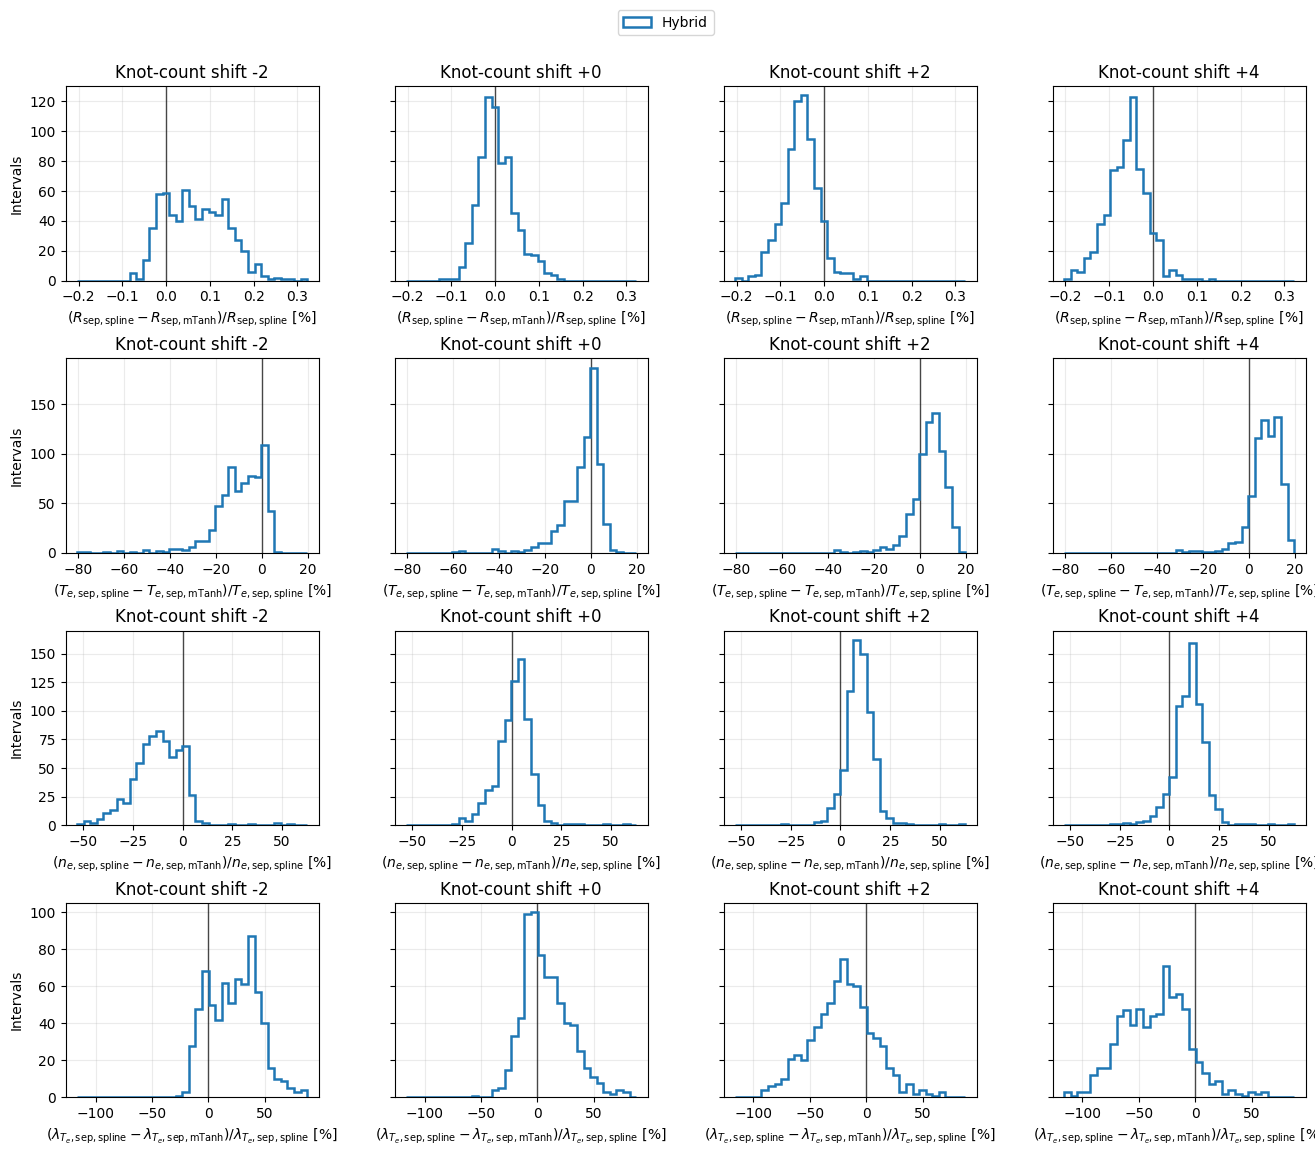

In [18]:
if comparison_data.empty:
    print('No successful scan rows to plot.')
else:
    fig, axes = plt.subplots(
        len(QUANTITY_ORDER), len(SHIFT_ORDER),
        figsize=(4.0 * len(SHIFT_ORDER), 3.2 * len(QUANTITY_ORDER)),
        sharey='row', squeeze=False,
    )
    fig.subplots_adjust(top=0.90, hspace=0.4, wspace=0.3)
    color_map = plt.get_cmap('tab10')
    strategy_colors = {
        strategy: color_map(index)
        for index, strategy in enumerate(STRATEGIES_TO_COMPARE)
    }

    for row_index, quantity in enumerate(QUANTITY_ORDER):
        difference_column = f'{quantity}_difference_pct'
        all_values = comparison_data[difference_column].dropna().to_numpy(float)
        if all_values.size:
            bin_edges = np.histogram_bin_edges(all_values, bins=HIST_BINS)
        else:
            bin_edges = np.linspace(-1.0, 1.0, HIST_BINS + 1)

        for column_index, shift in enumerate(SHIFT_ORDER):
            axis = axes[row_index, column_index]
            shift_rows = comparison_data.loc[
                comparison_data['knot_count_shift'].eq(shift)]
            axis.set_title(f'Knot-count shift {shift:+d}')
            axis.axvline(0.0, color='black', linewidth=1.0, alpha=0.7)
            has_histogram = False
            for strategy in STRATEGIES_TO_COMPARE:
                values = shift_rows.loc[
                    shift_rows['knot_strategy'].eq(strategy),
                    difference_column,
                ].dropna().to_numpy(float)
                if values.size == 0:
                    continue
                axis.hist(
                    values,
                    bins=bin_edges,
                    density=HIST_DENSITY,
                    histtype='step',
                    linewidth=1.8,
                    color=strategy_colors[strategy],
                    label=STRATEGY_LABELS.get(strategy, strategy),
                )
                has_histogram = True
            if not has_histogram:
                axis.text(
                    0.5, 0.5, 'No valid paired values',
                    ha='center', va='center', transform=axis.transAxes,
                )
            axis.set_xlabel(DIFFERENCE_SPECS[quantity]['label'])
            if column_index == 0:
                axis.set_ylabel(
                    'Probability density' if HIST_DENSITY else 'Intervals')

    legend_handles, legend_labels = axes[0, 0].get_legend_handles_labels()
    if legend_handles:
        fig.legend(
            legend_handles, legend_labels,
            loc='upper center', ncol=max(1, len(legend_labels)),
            bbox_to_anchor=(0.5, 0.965),
        )
    #fig.suptitle(
    #    f'Spline minus mTanh relative to spline | {selected_group_label}',
    #    y=0.995,
    #)
    plt.show()


In [19]:
STRATEGIES_TO_COMPARE[0]

'hybrid'

Paired successful intervals: 710 | strategy=hybrid | shift=+2 | All shot groups


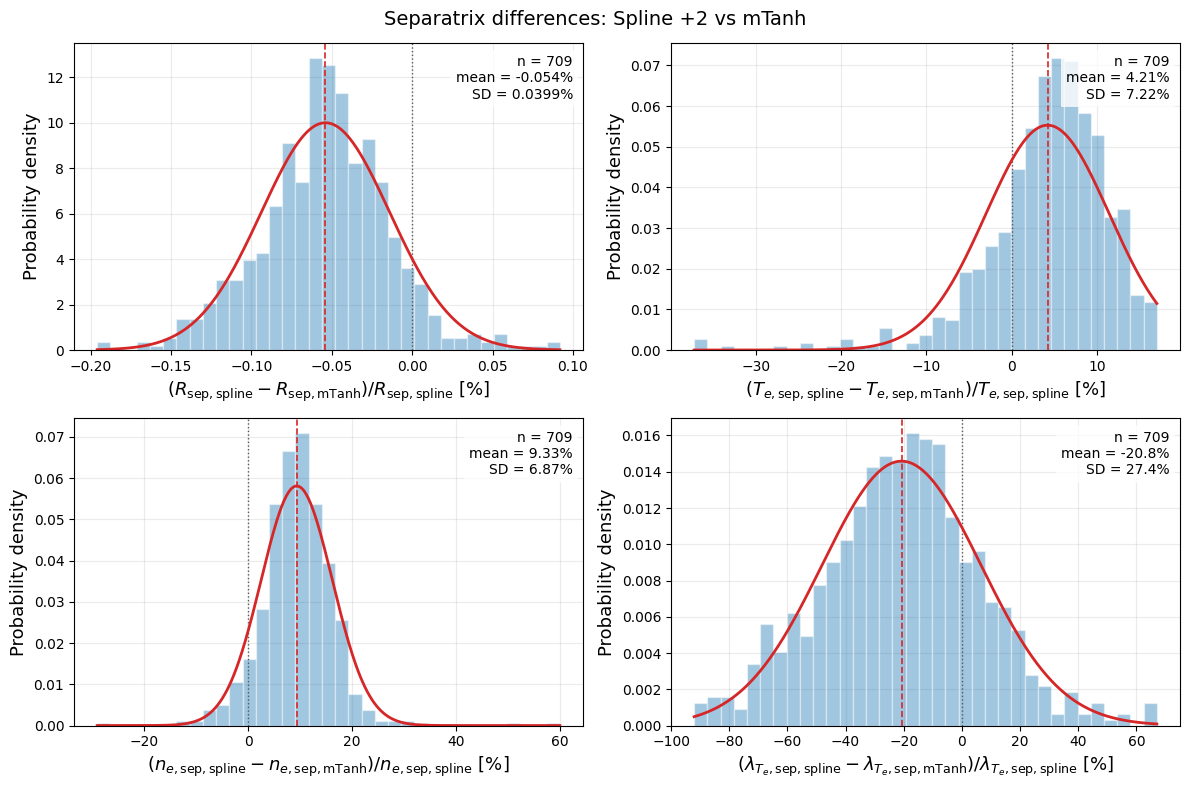

,quantity,n,mean difference (%),SD (%),median (%),Q1 (%),Q3 (%),skewness
0,R_sep,709,-0.053955,0.039914,-0.052822,-0.077661,-0.030096,0.006731
1,Te_sep,709,4.205723,7.216134,4.999241,1.059623,8.871119,-1.677151
2,Ne_sep,709,9.329295,6.868285,9.405192,5.655410,13.201350,0.533537
3,lambda_Te_sep,709,-20.758355,27.354843,-19.683605,-38.421857,-3.806092,0.077730


Pronounced asymmetry (|skewness| > 1) in: Te_sep. Interpret its Gaussian overlay cautiously; use the median and interquartile range alongside mean and SD.
Differences are 100 * (spline - mTanh) / spline; positive values mean the spline estimate is larger. Gaussian curves are moment-matched descriptive overlays, not a claim that the distributions are normal.


In [20]:
# Paired mTanh vs spline separatrix differences for one knot-count shift.
gaussian_shift = 2
shift_label = f'{gaussian_shift:+d}'

if len(STRATEGIES_TO_COMPARE) != 1:
    raise ValueError('Choose exactly one spline strategy for the paired comparison.')

gaussian_strategy = STRATEGIES_TO_COMPARE[0]

gaussian_source = joined.copy()
gaussian_source['fit_success'] = (
    gaussian_source['fit_success'].astype(str).str.strip().str.lower()
    .isin({'true', '1', 'yes'})
)
gaussian_source['knot_count_shift'] = pd.to_numeric(
    gaussian_source['knot_count_shift'], errors='coerce')
gaussian_source = gaussian_source.loc[
    gaussian_source['fit_success']
    & gaussian_source['fitted_db_match'].eq('both')
    & gaussian_source['knot_strategy'].eq(gaussian_strategy)
    & gaussian_source['knot_count_shift'].eq(gaussian_shift)
].copy()

if GROUP_PATTERNS:
    gaussian_group_regex = '|'.join(re.escape(pattern) for pattern in GROUP_PATTERNS)
    gaussian_source = gaussian_source.loc[
        gaussian_source['description'].str.contains(
            gaussian_group_regex, case=False, regex=True, na=False)
    ].copy()

if gaussian_source.duplicated(JOIN_KEYS).any():
    raise ValueError(f'The shift {shift_label} comparison contains duplicate interval keys.')
if gaussian_source.empty:
    raise ValueError(
        f'No successful, matched intervals found for {gaussian_strategy} shift {shift_label}.'
    )

print(
    f'Paired successful intervals: {len(gaussian_source)} | '
    f'strategy={gaussian_strategy} | shift={shift_label} | {selected_group_label}'
)

gaussian_summary_rows = []
gaussian_values_by_quantity = {}
for gaussian_quantity in QUANTITY_ORDER:
    gaussian_fields = DIFFERENCE_SPECS[gaussian_quantity]
    gaussian_values = spline_relative_percentage_difference(
        gaussian_source[gaussian_fields['mtanh']],
        gaussian_source[gaussian_fields['spline']],
    )
    gaussian_values = gaussian_values[np.isfinite(gaussian_values)]
    gaussian_values_by_quantity[gaussian_quantity] = gaussian_values
    if gaussian_values.size:
        gaussian_summary_rows.append({
            'quantity': gaussian_quantity,
            'n': gaussian_values.size,
            'mean difference (%)': np.mean(gaussian_values),
            'SD (%)': np.std(gaussian_values, ddof=1) if gaussian_values.size > 1 else np.nan,
            'median (%)': np.median(gaussian_values),
            'Q1 (%)': np.percentile(gaussian_values, 25),
            'Q3 (%)': np.percentile(gaussian_values, 75),
            'skewness': pd.Series(gaussian_values).skew(),
        })
    else:
        gaussian_summary_rows.append({
            'quantity': gaussian_quantity,
            'n': 0,
            'mean difference (%)': np.nan,
            'SD (%)': np.nan,
            'median (%)': np.nan,
            'Q1 (%)': np.nan,
            'Q3 (%)': np.nan,
            'skewness': np.nan,
        })

fig, gaussian_axes = plt.subplots(2, 2, figsize=(12, 8), squeeze=False)
for gaussian_axis, gaussian_quantity in zip(gaussian_axes.flat, QUANTITY_ORDER):
    gaussian_values = gaussian_values_by_quantity[gaussian_quantity]
    gaussian_axis.axvline(0.0, color='0.35', linewidth=1.0, linestyle=':')
    if gaussian_values.size:
        gaussian_axis.hist(
            gaussian_values,
            bins=HIST_BINS,
            density=True,
            color='tab:blue',
            alpha=0.42,
            edgecolor='white',
            label='Differences',
        )
        gaussian_mean = float(np.mean(gaussian_values))
        gaussian_sd = float(np.std(gaussian_values, ddof=1)) if gaussian_values.size > 1 else np.nan
        if gaussian_values.size > 1 and np.isfinite(gaussian_sd) and gaussian_sd > 0.0:
            gaussian_x = np.linspace(gaussian_values.min(), gaussian_values.max(), 400)
            gaussian_pdf = np.exp(
                -0.5 * ((gaussian_x - gaussian_mean) / gaussian_sd) ** 2
            ) / (gaussian_sd * np.sqrt(2.0 * np.pi))
            gaussian_axis.plot(
                gaussian_x, gaussian_pdf,
                color='tab:red', linewidth=2.0,
                label='Gaussian Fit',
            )
        gaussian_axis.axvline(
            gaussian_mean, color='tab:red', linewidth=1.2, linestyle='--',
            label=f'Mean = {gaussian_mean:.3g}%',
        )
        gaussian_axis.text(
            0.98, 0.96,
            f'n = {gaussian_values.size}\nmean = {gaussian_mean:.3g}%\n'
            f'SD = {gaussian_sd:.3g}%' if np.isfinite(gaussian_sd)
            else f'n = {gaussian_values.size}\nmean = {gaussian_mean:.3g}%\nSD = n/a',
            ha='right', va='top', transform=gaussian_axis.transAxes,
            bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'},
        )
    else:
        gaussian_axis.text(
            0.5, 0.5, 'No valid paired values',
            ha='center', va='center', transform=gaussian_axis.transAxes,
        )
    gaussian_axis.set_xlabel(DIFFERENCE_SPECS[gaussian_quantity]['label'], fontsize=13)
    gaussian_axis.set_ylabel('Probability density', fontsize=13)
    #gaussian_axis.legend(fontsize=8)

fig.suptitle(
    f'Separatrix differences: Spline {shift_label} vs mTanh',
    #f'{selected_group_label}',
    y=0.98, fontsize=14
)
fig.tight_layout()
plt.show()

gaussian_difference_summary = pd.DataFrame(gaussian_summary_rows)
display(gaussian_difference_summary)
strongly_skewed = gaussian_difference_summary.loc[
    gaussian_difference_summary['skewness'].abs().gt(1.0), 'quantity'
].tolist()
if strongly_skewed:
    print(
        'Pronounced asymmetry (|skewness| > 1) in: '
        f'{", ".join(strongly_skewed)}. Interpret its Gaussian overlay cautiously; '
        'use the median and interquartile range alongside mean and SD.'
    )
print(
    'Differences are 100 * (spline - mTanh) / spline; positive values mean '
    'the spline estimate is larger. Gaussian curves are moment-matched '
    'descriptive overlays, not a claim that the distributions are normal.'
)


In [21]:
# Paired spline-minus-mTanh separatrix differences in native units, on the rows of the paired cell above.
EV_M3_TO_KPA = 1.602176634e-22  # Pipeline convention: p_e [kPa] = n_e [m^-3] * T_e [eV] * 1.602176634e-22


def numeric_column(frame, column):
    return pd.to_numeric(frame[column], errors='coerce').to_numpy(float)


mtanh_pressure = (
    numeric_column(gaussian_source, 'mtanh_Ne_sep')
    * numeric_column(gaussian_source, 'mtanh_Te_sep')
    * EV_M3_TO_KPA
)
spline_pressure = (
    numeric_column(gaussian_source, 'Ne_at_Rsep_m3')
    * numeric_column(gaussian_source, 'Te_at_Rsep_eV')
    * EV_M3_TO_KPA
)

# (row label, mTanh values, spline values, scale to native units, decimals)
table_specs = [
    (
        r'\Rsep{}\,[mm]',
        numeric_column(gaussian_source, 'mtanh_Rsep'),
        numeric_column(gaussian_source, 'Rsep_spline_m'),
        1e3, 2,
    ),
    (
        r'\Tesep\,[eV]',
        numeric_column(gaussian_source, 'mtanh_Te_sep'),
        numeric_column(gaussian_source, 'Te_at_Rsep_eV'),
        1.0, 2,
    ),
    (
        r'\Nesep\,[$10^{19}\,\mathrm{m^{-3}}$]',
        numeric_column(gaussian_source, 'mtanh_Ne_sep'),
        numeric_column(gaussian_source, 'Ne_at_Rsep_m3'),
        1e-19, 3,
    ),
    (
        r'$p_{e,\mathrm{sep}}$ [kPa]',
        mtanh_pressure,
        spline_pressure,
        1.0, 3,
    ),
    (
        r'\lamTesep\,[mm]',
        numeric_column(gaussian_source, 'mtanh_lambda_Te_sep'),
        numeric_column(gaussian_source, 'lambda_Te_sep_m'),
        1e3, 2,
    ),
    (
        r'$\lambda_{n_e,\mathrm{sep}}$ [mm]',
        numeric_column(gaussian_source, 'mtanh_lambda_Ne_sep'),
        numeric_column(gaussian_source, 'lambda_Ne_sep_m'),
        1e3, 2,
    ),
]

table_rows = []
for label, mtanh_values, spline_values, scale, decimals in table_specs:
    valid = (
        np.isfinite(mtanh_values)
        & np.isfinite(spline_values)
        & (spline_values != 0.0)
    )
    raw_difference = spline_values[valid] - mtanh_values[valid]
    diff = scale * raw_difference
    mean, sd = np.mean(diff), np.std(diff, ddof=1)
    q1, median, q3 = np.percentile(diff, [25, 50, 75])
    rel_mean = np.mean(100.0 * raw_difference / spline_values[valid])
    spline_higher = 100.0 * np.mean(raw_difference > 0.0)
    table_rows.append(
        f"{label} & ${mean:+.{decimals}f} \\pm {sd:.{decimals}f}$ & "
        f"${median:+.{decimals}f}\\,[{q1:+.{decimals}f},{q3:+.{decimals}f}]$ & "
        f"{rel_mean:+.1f} & {spline_higher:.1f} & {diff.size} \\\\"
    )

latex_separatrix_table = '\n'.join([
    r'\includetable{%',
    r'\caption{Separatrix-parameter differences for the ' + strategy_label
    + r' spline with a $' + shift_label
    + r'$ knot-count shift relative to the modified-tanh fit, for '
    + str(len(gaussian_source)) + r' paired intervals. Differences are spline minus mTanh in native units, given as mean $\pm$ SD and median [Q1, Q3]. Rel. is the mean of $100\,(x_{\mathrm{spline}}-x_{\mathrm{mTanh}})/x_{\mathrm{spline}}$ [\%], and Spline $>$ mTanh is the percentage of pairs with a positive difference. $n$ is the number of finite pairs per row, and $p_{e,\mathrm{sep}}=n_{e,\mathrm{sep}}\,T_{e,\mathrm{sep}}\times1.602\times10^{-22}$ in kPa.}',
    r'\label{tab:separatrix-parameter-differences}',
    r'\small',
    r'\begin{tabular}{lrrrrr}',
    r'\toprule',
    r'Quantity & Mean $\pm$ SD & Median [Q1, Q3] & Rel. [\%] & Spline $>$ mTanh [\%] & $n$ \\',
    r'\midrule',
    *table_rows,
    r'\bottomrule',
    r'\end{tabular}',
    '}',
])
print(latex_separatrix_table)

\includetable{%
\caption{Separatrix-parameter differences for the Hybrid spline with a $+2$ knot-count shift relative to the modified-tanh fit, for 710 paired intervals. Differences are spline minus mTanh in native units, given as mean $\pm$ SD and median [Q1, Q3]. Rel. is the mean of $100\,(x_{\mathrm{spline}}-x_{\mathrm{mTanh}})/x_{\mathrm{spline}}$ [\%], and Spline $>$ mTanh is the percentage of pairs with a positive difference. $n$ is the number of finite pairs per row, and $p_{e,\mathrm{sep}}=n_{e,\mathrm{sep}}\,T_{e,\mathrm{sep}}\times1.602\times10^{-22}$ in kPa.}
\label{tab:separatrix-parameter-differences}
\small
\begin{tabular}{lrrrrr}
\toprule
Quantity & Mean $\pm$ SD & Median [Q1, Q3] & Rel. [\%] & Spline $>$ mTanh [\%] & $n$ \\
\midrule
\Rsep{}\,[mm] & $-1.16 \pm 0.86$ & $-1.13\,[-1.66,-0.64]$ & -0.1 & 7.1 & 709 \\
\Tesep\,[eV] & $+4.39 \pm 7.44$ & $+5.03\,[+1.02,+8.76]$ & +4.2 & 79.3 & 709 \\
\Nesep\,[$10^{19}\,\mathrm{m^{-3}}$] & $+0.238 \pm 0.196$ & $+0.200\,[+0.108,+0.3

In [10]:
plots[]

SyntaxError: invalid syntax (321262282.py, line 1)

In [ ]:
THESIS_FIGURE_PATH = (
    PROJECT_ROOT.parent
    / 'TESE_Joao_Pedro_Nunes'
    / 'chapters'
    / 'Formulation_and_Methods'
    / 'Separatrix_Physics'
    / 'figures'
    / 'separatrix_parameters_differences_spline_plus2.pdf'
)
if not THESIS_FIGURE_PATH.parent.is_dir():
    raise FileNotFoundError(f'Thesis figure directory not found: {THESIS_FIGURE_PATH.parent}')
fig.savefig(THESIS_FIGURE_PATH, format='pdf', bbox_inches='tight')
print(f'Saved figure: {THESIS_FIGURE_PATH}')

Saved figure: /shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Separatrix_Physics/figures/separatrix_parameters_differences_spline_plus2.pdf


In [ ]:
savwe

,quantity,knot_count_shift,n,median_n_knots,median_pct,Q1_pct,Q3_pct
0,Ne_sep,-2,710,14.0,-10.934449,-17.465443,-5.424808
1,Ne_sep,2,710,18.0,8.794633,3.134872,14.772984
2,Ne_sep,4,709,20.0,9.357109,2.527945,16.939138
3,R_sep,-2,710,14.0,0.052675,0.014189,0.106121
4,R_sep,2,710,18.0,-0.068890,-0.091539,-0.028359
5,R_sep,4,709,20.0,-0.075991,-0.101662,-0.031650
6,Te_sep,-2,710,14.0,-3.438467,-7.358355,-1.905745
7,Te_sep,2,710,18.0,8.789617,3.570339,13.519632
8,Te_sep,4,709,20.0,12.365869,8.025995,16.470698
9,lambda_Te_sep,-2,710,14.0,13.039298,6.968473,30.674853


Saved figure: /shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Separatrix_Physics/figures/separatrix_spline_knot_shift_differences.pdf


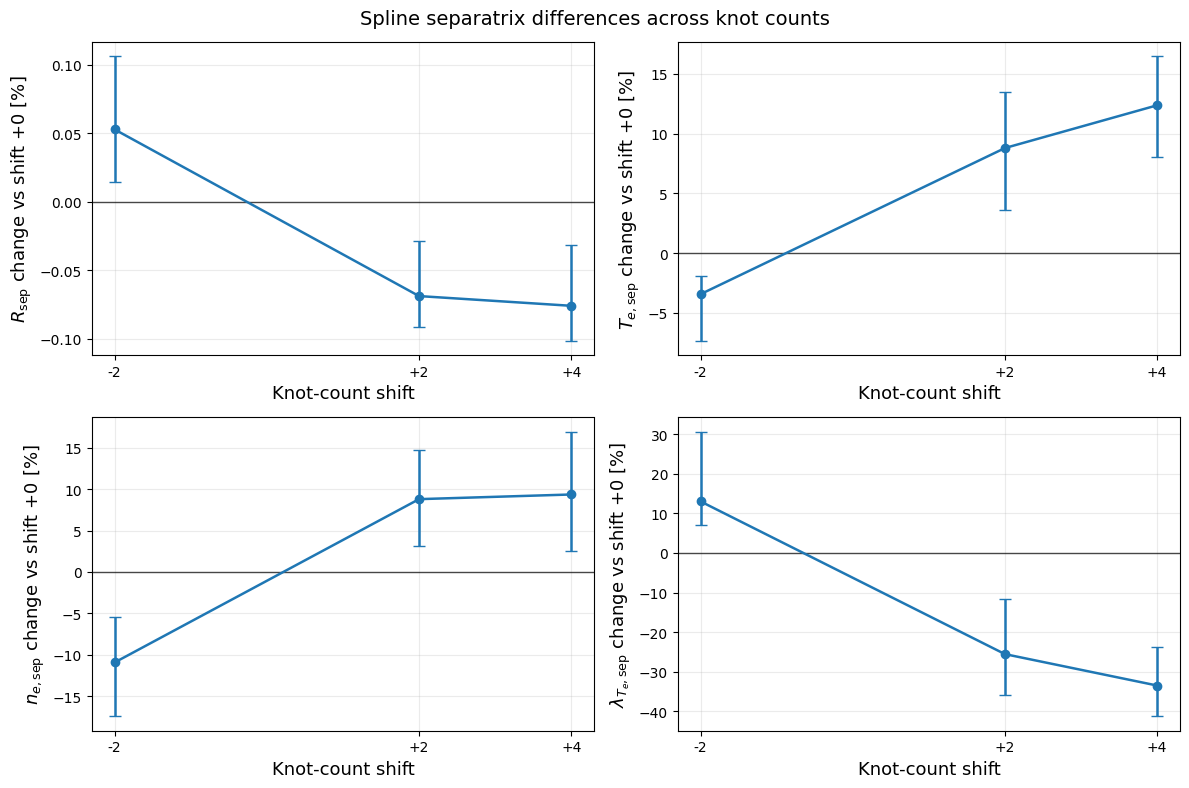

In [12]:
# Spline-to-spline separatrix differences relative to the reference knot count.
REFERENCE_SHIFT = 0
if REFERENCE_SHIFT not in SHIFT_ORDER:
    raise ValueError(f'REFERENCE_SHIFT={REFERENCE_SHIFT} must be in KNOT_SHIFTS_TO_COMPARE.')

COMPARISON_LABELS = {
    'R_sep': r'$R_{\mathrm{sep}}$',
    'Te_sep': r'$T_{e,\mathrm{sep}}$',
    'Ne_sep': r'$n_{e,\mathrm{sep}}$',
    'lambda_Te_sep': r'$\lambda_{T_e,\mathrm{sep}}$',
}

pair_keys = JOIN_KEYS + ['knot_strategy']
spline_columns = [DIFFERENCE_SPECS[quantity]['spline'] for quantity in QUANTITY_ORDER]
spline_source = successful_scan.loc[
    :, pair_keys + ['knot_count_shift', 'n_knots'] + spline_columns
].copy()
reference_splines = spline_source.loc[
    spline_source['knot_count_shift'].eq(REFERENCE_SHIFT),
    pair_keys + spline_columns,
]

shift_difference_frames = []
for shift in SHIFT_ORDER:
    if shift == REFERENCE_SHIFT:
        continue
    variant = spline_source.loc[spline_source['knot_count_shift'].eq(shift)]
    paired = variant.merge(
        reference_splines, on=pair_keys, suffixes=('', '_ref'),
        how='inner', validate='one_to_one',
    )
    for quantity in QUANTITY_ORDER:
        spline_column = DIFFERENCE_SPECS[quantity]['spline']
        reference_values = paired[f'{spline_column}_ref'].to_numpy(float)
        variant_values = paired[spline_column].to_numpy(float)
        valid = (
            np.isfinite(reference_values)
            & np.isfinite(variant_values)
            & (reference_values != 0.0)
        )
        shift_difference_frames.append(pd.DataFrame({
            'quantity': quantity,
            'knot_count_shift': shift,
            'n_knots': paired['n_knots'].to_numpy(float)[valid],
            'difference_pct': 100.0 * (
                variant_values[valid] - reference_values[valid]
            ) / reference_values[valid],
        }))

spline_shift_differences = pd.concat(shift_difference_frames, ignore_index=True)
if spline_shift_differences.empty:
    raise ValueError(
        f'No intervals have successful spline fits at shift {REFERENCE_SHIFT:+d} '
        'and at the compared shifts.'
    )

spline_shift_summary = (
    spline_shift_differences
    .groupby(['quantity', 'knot_count_shift'])
    .agg(
        n=('difference_pct', 'size'),
        median_n_knots=('n_knots', 'median'),
        median_pct=('difference_pct', 'median'),
        Q1_pct=('difference_pct', lambda values: values.quantile(0.25)),
        Q3_pct=('difference_pct', lambda values: values.quantile(0.75)),
    )
    .reset_index()
)
display(spline_shift_summary)

compared_shifts = [shift for shift in SHIFT_ORDER if shift != REFERENCE_SHIFT]
fig, spline_axes = plt.subplots(2, 2, figsize=(12, 8), squeeze=False)
for spline_axis, quantity in zip(spline_axes.flat, QUANTITY_ORDER):
    quantity_rows = (
        spline_shift_summary.loc[spline_shift_summary['quantity'].eq(quantity)]
        .set_index('knot_count_shift')
        .reindex(compared_shifts)
    )
    x_positions = np.asarray(compared_shifts, dtype=float)
    median = quantity_rows['median_pct'].to_numpy(float)
    lower = median - quantity_rows['Q1_pct'].to_numpy(float)
    upper = quantity_rows['Q3_pct'].to_numpy(float) - median
    spline_axis.axhline(0.0, color='black', linewidth=1.0, alpha=0.7)
    spline_axis.errorbar(
        x_positions, median, yerr=[lower, upper],
        marker='o', linewidth=1.8, capsize=4, color='tab:blue',
    )
    spline_axis.set_xticks(x_positions)
    spline_axis.set_xticklabels([f'{shift:+d}' for shift in compared_shifts])
    spline_axis.set_xlabel('Knot-count shift', fontsize=13)
    spline_axis.set_ylabel(
        f'{COMPARISON_LABELS[quantity]} change vs shift {REFERENCE_SHIFT:+d} [%]',
        fontsize=13,
    )

fig.suptitle(
    f'Spline separatrix differences across knot counts',
    #f'{strategy_label} | '
    #f'{selected_group_label}',
    y=0.98, fontsize=14,
)
fig.tight_layout()

THESIS_SPLINE_FIGURE_PATH = (
    PROJECT_ROOT.parent
    / 'TESE_Joao_Pedro_Nunes'
    / 'chapters'
    / 'Formulation_and_Methods'
    / 'Separatrix_Physics'
    / 'figures'
    / 'separatrix_spline_knot_shift_differences.pdf'
)
if not THESIS_SPLINE_FIGURE_PATH.parent.is_dir():
    raise FileNotFoundError(f'Thesis figure directory not found: {THESIS_SPLINE_FIGURE_PATH.parent}')
fig.savefig(THESIS_SPLINE_FIGURE_PATH, format='pdf', bbox_inches='tight')
print(f'Saved figure: {THESIS_SPLINE_FIGURE_PATH}')
plt.show()

## 7. Compare Raw Weighted Chi-Squared Distributions

The mTanh weighted-$\\chi^2$ values come from the fitted database, and spline values come from successful scan rows matched to the fitted database. Te and Ne distributions use the same bins and shot-group filter.

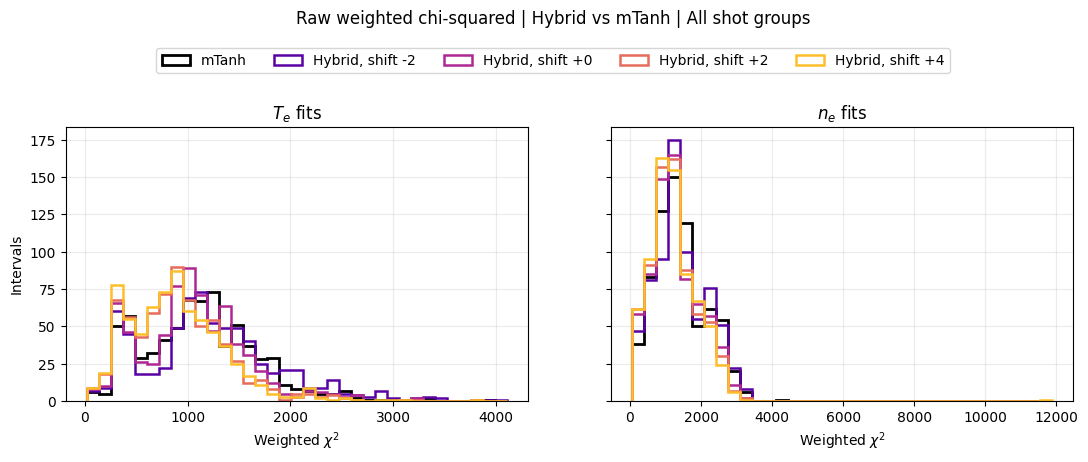

In [ ]:
chi2_plot_scan = scan_raw.copy()
chi2_plot_scan['shot_id'] = pd.to_numeric(
    chi2_plot_scan['shot_id'], errors='raise').astype(int)
for time_column in ('t_begin', 't_end'):
    chi2_plot_scan[time_column] = pd.to_numeric(
        chi2_plot_scan[time_column], errors='coerce').round(9)
chi2_plot_scan['fit_success'] = (
    chi2_plot_scan['fit_success'].astype(str).str.strip().str.lower()
    .isin({'true', '1', 'yes'})
)
if GROUP_PATTERNS:
    chi2_plot_scan = chi2_plot_scan.merge(
        shot_groups_raw[SHOT_GROUP_COLUMNS].drop_duplicates('shot_id'),
        on='shot_id',
        how='left',
        validate='many_to_one',
    )
    group_regex = '|'.join(re.escape(pattern) for pattern in GROUP_PATTERNS)
    chi2_plot_scan = chi2_plot_scan.loc[
        chi2_plot_scan['description'].str.contains(
            group_regex, case=False, regex=True, na=False)
    ].copy()
chi2_plot_scan = chi2_plot_scan.loc[
    chi2_plot_scan['fit_success']
    & chi2_plot_scan['knot_strategy'].eq(strategy_to_compare)
    & chi2_plot_scan['knot_count_shift'].isin(SHIFT_ORDER)
].copy()

chi2_baseline = fitted_raw.rename(columns={
    'shot': 'shot_id',
    't_begin (s)': 't_begin',
    't_end (s)': 't_end',
}).copy()
chi2_baseline['shot_id'] = pd.to_numeric(
    chi2_baseline['shot_id'], errors='raise').astype(int)
for time_column in ('t_begin', 't_end'):
    chi2_baseline[time_column] = pd.to_numeric(
        chi2_baseline[time_column], errors='coerce').round(9)
chi2_baseline_columns = JOIN_KEYS + [
    'mtanh_Te_weighted_sse', 'mtanh_Ne_weighted_sse',
]
missing_chi2_columns = sorted(
    set(chi2_baseline_columns).difference(chi2_baseline.columns)
    | {'Te_chi_squared', 'Ne_chi_squared'}.difference(chi2_plot_scan.columns)
)
if missing_chi2_columns:
    raise ValueError(f'Missing weighted chi-squared columns: {missing_chi2_columns}')
chi2_baseline = chi2_baseline.loc[:, chi2_baseline_columns]
if chi2_baseline.duplicated(JOIN_KEYS).any():
    raise ValueError('The fitted database has duplicate interval keys.')
chi2_plot_data = chi2_plot_scan.merge(
    chi2_baseline,
    on=JOIN_KEYS,
    how='inner',
    validate='many_to_one',
)

CHI_SQUARED_SPECS = {
    'Te': {
        'mtanh': 'mtanh_Te_weighted_sse',
        'spline': 'Te_chi_squared',
        'title': r'$T_e$ fits',
    },
    'Ne': {
        'mtanh': 'mtanh_Ne_weighted_sse',
        'spline': 'Ne_chi_squared',
        'title': r'$n_e$ fits',
    },
}
shift_color_map = plt.get_cmap('plasma')
shift_positions = np.linspace(0.16, 0.86, len(SHIFT_ORDER))
shift_colors = {
    shift: shift_color_map(position)
    for shift, position in zip(SHIFT_ORDER, shift_positions)
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
fig.subplots_adjust(top=0.72, wspace=0.18)

for axis, (quantity, fields) in zip(axes, CHI_SQUARED_SPECS.items()):
    distributions = []
    interval_rows = chi2_plot_data.drop_duplicates(JOIN_KEYS)
    baseline_values = pd.to_numeric(
        interval_rows[fields['mtanh']], errors='coerce').to_numpy(float)
    baseline_values = baseline_values[
        np.isfinite(baseline_values) & (baseline_values >= 0.0)]
    if baseline_values.size:
        distributions.append(baseline_values)

    spline_values_by_shift = {}
    for shift in SHIFT_ORDER:
        spline_values = pd.to_numeric(
            chi2_plot_data.loc[
                chi2_plot_data['knot_count_shift'].eq(shift),
                fields['spline'],
            ],
            errors='coerce',
        ).to_numpy(float)
        spline_values = spline_values[np.isfinite(spline_values) & (spline_values >= 0.0)]
        if spline_values.size:
            spline_values_by_shift[shift] = spline_values
            distributions.append(spline_values)

    combined_values = (
        np.concatenate(distributions) if distributions else np.array([]))
    bin_edges = (
        np.histogram_bin_edges(combined_values, bins=HIST_BINS)
        if combined_values.size else np.linspace(0.0, 1.0, HIST_BINS + 1)
    )
    if baseline_values.size:
        axis.hist(
            baseline_values,
            bins=bin_edges,
            density=HIST_DENSITY,
            histtype='step',
            linewidth=2.0,
            color='black',
            label='mTanh',
        )
    for shift, spline_values in spline_values_by_shift.items():
        axis.hist(
            spline_values,
            bins=bin_edges,
            density=HIST_DENSITY,
            histtype='step',
            linewidth=1.8,
            color=shift_colors[shift],
            label=f'{strategy_label}, shift {shift:+d}',
        )
    axis.set_title(fields['title'])
    axis.set_xlabel(r'Weighted $\chi^2$')
    if not distributions:
        axis.text(0.5, 0.5, 'No valid chi-squared values',
                  ha='center', va='center', transform=axis.transAxes)

axes[0].set_ylabel(
    'Probability density' if HIST_DENSITY else 'Intervals')
handles = []
labels = []
for axis in axes:
    current_handles, current_labels = axis.get_legend_handles_labels()
    for handle, label in zip(current_handles, current_labels):
        if label not in labels:
            handles.append(handle)
            labels.append(label)
if handles:
    fig.legend(
        handles, labels, loc='upper center',
        ncol=1 + len(SHIFT_ORDER), bbox_to_anchor=(0.5, 0.91),
    )
fig.suptitle(
    f'Raw weighted chi-squared | {strategy_label} vs mTanh | {selected_group_label}',
    y=0.98,
)
plt.show()


Fitted database CSV: /shares/users/work/joanune/Desktop/TS_profile_fitter/results/EQH_run_06_for_thesis/34383---38808_database_dt-0.1s_fitted.csv
Successful selected spline variants: 2839
Unmatched raw scan rows: 0
Unmatched fitted CSV intervals: 0


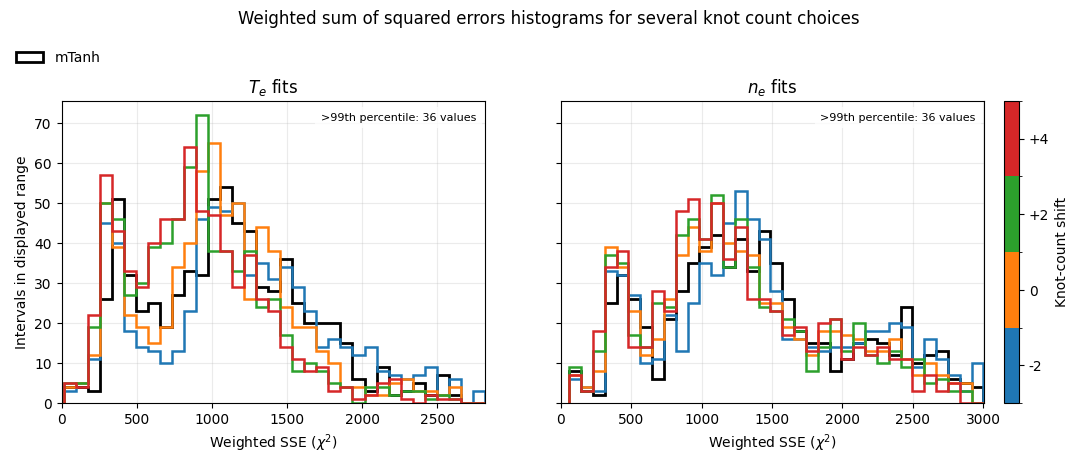

Each x-axis is capped at the pooled 99th percentile for that quantity. Values above the limit are omitted from the displayed bins only; the source data are unchanged.


,quantity,fit model,values above display limit
0,Te,mTanh,6
1,Te,"Hybrid, shift -2",20
2,Te,"Hybrid, shift +0",3
3,Te,"Hybrid, shift +2",3
4,Te,"Hybrid, shift +4",4
5,Ne,mTanh,13
6,Ne,"Hybrid, shift -2",11
7,Ne,"Hybrid, shift +0",4
8,Ne,"Hybrid, shift +2",4
9,Ne,"Hybrid, shift +4",4


In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import BoundaryNorm, ListedColormap

HISTOGRAM_UPPER_PERCENTILE = 99.0

RAW_SSE_SPECS = {
    'Te': {
        'mtanh': 'mtanh_Te_weighted_sse',
        'spline': 'Te_chi_squared',
        'title': r'$T_e$ fits',
    },
    'Ne': {
        'mtanh': 'mtanh_Ne_weighted_sse',
        'spline': 'Ne_chi_squared',
        'title': r'$n_e$ fits',
    },
}

fitted_csv_path = FITTED_DATABASE_PATH.with_suffix('.csv')
if not fitted_csv_path.is_file():
    raise FileNotFoundError(f'Fitted database CSV not found: {fitted_csv_path}')

raw_fitted_csv = pd.read_csv(fitted_csv_path).rename(columns={
    'shot': 'shot_id',
    't_begin (s)': 't_begin',
    't_end (s)': 't_end',
})
raw_variant_keys = JOIN_KEYS + ['knot_strategy', 'knot_count_shift']
raw_fit_columns = [fields['mtanh'] for fields in RAW_SSE_SPECS.values()]
raw_spline_columns = [fields['spline'] for fields in RAW_SSE_SPECS.values()]
missing_raw_fields = sorted(
    set(JOIN_KEYS + raw_fit_columns).difference(raw_fitted_csv.columns)
    | set(raw_variant_keys + raw_spline_columns).difference(scan_raw.columns)
)
if missing_raw_fields:
    raise ValueError(f'Missing unreduced chi-squared fields: {missing_raw_fields}')

raw_mtanh = raw_fitted_csv.loc[:, JOIN_KEYS + raw_fit_columns].copy()
raw_spline = scan_raw.loc[:, raw_variant_keys + raw_spline_columns].copy()
for frame in (raw_mtanh, raw_spline):
    frame['shot_id'] = pd.to_numeric(frame['shot_id'], errors='raise').astype(int)
    for time_column in ('t_begin', 't_end'):
        frame[time_column] = pd.to_numeric(
            frame[time_column], errors='coerce').round(9)

if raw_mtanh.duplicated(JOIN_KEYS).any():
    raise ValueError('The fitted CSV has duplicate shot-interval keys.')
if raw_spline.duplicated(raw_variant_keys).any():
    raise ValueError('The scan CSV has duplicate strategy/shift interval keys.')

raw_sse_data = comparison_data.merge(
    raw_spline,
    on=raw_variant_keys,
    how='left',
    validate='one_to_one',
    indicator='_raw_scan_match',
).merge(
    raw_mtanh,
    on=JOIN_KEYS,
    how='left',
    validate='many_to_one',
    indicator='_raw_db_match',
)
print(f'Fitted database CSV: {fitted_csv_path}')
print(f'Successful selected spline variants: {len(raw_sse_data)}')
print('Unmatched raw scan rows:', int(raw_sse_data['_raw_scan_match'].ne('both').sum()))
print('Unmatched fitted CSV intervals:', int(raw_sse_data['_raw_db_match'].ne('both').sum()))

raw_mtanh_baseline = (
    raw_sse_data.loc[:, JOIN_KEYS + raw_fit_columns]
    .drop_duplicates(JOIN_KEYS)
)
shift_color_map = ListedColormap(
    plt.get_cmap('tab10').colors[:len(SHIFT_ORDER)],
    name='tab10_knot_shifts',
)
shift_boundaries = np.arange(len(SHIFT_ORDER) + 1) - 0.5
shift_norm = BoundaryNorm(shift_boundaries, shift_color_map.N)
shift_colors = {
    shift: shift_color_map(index)
    for index, shift in enumerate(SHIFT_ORDER)
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
fig.subplots_adjust(top=0.80, bottom=0.17, right=0.88, wspace=0.18)
overflow_rows = []

for axis, (quantity, fields) in zip(axes, RAW_SSE_SPECS.items()):
    mtanh_values = pd.to_numeric(
        raw_mtanh_baseline[fields['mtanh']], errors='coerce').to_numpy(float)
    mtanh_values = mtanh_values[np.isfinite(mtanh_values) & (mtanh_values >= 0.0)]

    spline_values_by_shift = {}
    distributions = [mtanh_values] if mtanh_values.size else []
    for shift in SHIFT_ORDER:
        spline_values = pd.to_numeric(
            raw_sse_data.loc[
                raw_sse_data['knot_strategy'].eq(strategy_to_compare)
                & raw_sse_data['knot_count_shift'].eq(shift),
                fields['spline'],
            ],
            errors='coerce',
        ).to_numpy(float)
        spline_values = spline_values[
            np.isfinite(spline_values) & (spline_values >= 0.0)]
        if spline_values.size:
            spline_values_by_shift[shift] = spline_values
            distributions.append(spline_values)

    combined_values = (
        np.concatenate(distributions) if distributions else np.array([]))
    if combined_values.size:
        display_max = float(np.percentile(
            combined_values, HISTOGRAM_UPPER_PERCENTILE))
        in_range_values = combined_values[combined_values <= display_max]
        bin_edges = np.histogram_bin_edges(in_range_values, bins=HIST_BINS)
    else:
        display_max = 1.0
        bin_edges = np.linspace(0.0, display_max, HIST_BINS + 1)

    overflow_rows.append({
        'quantity': quantity,
        'fit model': 'mTanh',
        'values above display limit': int(np.count_nonzero(mtanh_values > display_max)),
    })
    if mtanh_values.size:
        axis.hist(
            mtanh_values,
            bins=bin_edges,
            density=HIST_DENSITY,
            histtype='step',
            linewidth=2.0,
            color='black',
            label='mTanh',
        )

    for shift, spline_values in spline_values_by_shift.items():
        overflow_rows.append({
            'quantity': quantity,
            'fit model': f'{strategy_label}, shift {shift:+d}',
            'values above display limit': int(np.count_nonzero(spline_values > display_max)),
        })
        axis.hist(
            spline_values,
            bins=bin_edges,
            density=HIST_DENSITY,
            histtype='step',
            linewidth=1.8,
            color=shift_colors[shift],
        )

    axis.set_xlim(0.0, display_max)
    axis.set_title(fields['title'])
    axis.set_xlabel(r'Weighted SSE ($\chi^2$)')
    overflow_total = sum(
        row['values above display limit']
        for row in overflow_rows if row['quantity'] == quantity
    )
    axis.text(
        0.98, 0.96,
        f'>{HISTOGRAM_UPPER_PERCENTILE:.0f}th percentile: {overflow_total} values',
        ha='right', va='top', transform=axis.transAxes, fontsize=8,
        bbox={'facecolor': 'white', 'alpha': 0.8, 'edgecolor': 'none'},
    )

axes[0].set_ylabel(
    'Probability density in displayed range'
    if HIST_DENSITY else 'Intervals in displayed range'
)
handles, labels = axes[0].get_legend_handles_labels()
if handles:
    fig.legend(
        handles, labels, loc='upper left',
        bbox_to_anchor=(0.08, 0.93), frameon=False,
    )
shift_colorbar = fig.colorbar(
    ScalarMappable(norm=shift_norm, cmap=shift_color_map),
    ax=axes,
    pad=0.02,
    fraction=0.04,
    boundaries=shift_boundaries,
    ticks=np.arange(len(SHIFT_ORDER)),
)
shift_colorbar.set_label('Knot-count shift')
shift_colorbar.ax.set_yticklabels([
    '0' if shift == 0 else f'{shift:+d}'
    for shift in SHIFT_ORDER
])
fig.suptitle(
    f'Weighted sum of squared errors histograms for several knot count choices',
    y=0.99,
)
plt.show()

print(
    f'Each x-axis is capped at the pooled {HISTOGRAM_UPPER_PERCENTILE:.0f}th '
    'percentile for that quantity. Values above the limit are omitted from the '
    'displayed bins only; the source data are unchanged.'
)
display(pd.DataFrame(overflow_rows))


In [ ]:
plots[]

In [ ]:
THESIS_FIGURE_PATH = (
    PROJECT_ROOT.parent
    / 'TESE_Joao_Pedro_Nunes'
    / 'chapters'
    / 'Formulation_and_Methods'
    / 'Profile_Fitting'
    / 'figures'
    / 'weighted_chi_squared_knot_shift_histograms.pdf'
)
if not THESIS_FIGURE_PATH.parent.is_dir():
    raise FileNotFoundError(f'Thesis figure directory not found: {THESIS_FIGURE_PATH.parent}')
fig.savefig(THESIS_FIGURE_PATH, format='pdf', bbox_inches='tight')
print(f'Saved figure: {THESIS_FIGURE_PATH}')

Saved figure: /shares/users/work/joanune/Desktop/TESE_Joao_Pedro_Nunes/chapters/Formulation_and_Methods/Profile_Fitting/figures/weighted_chi_squared_knot_shift_histograms.pdf


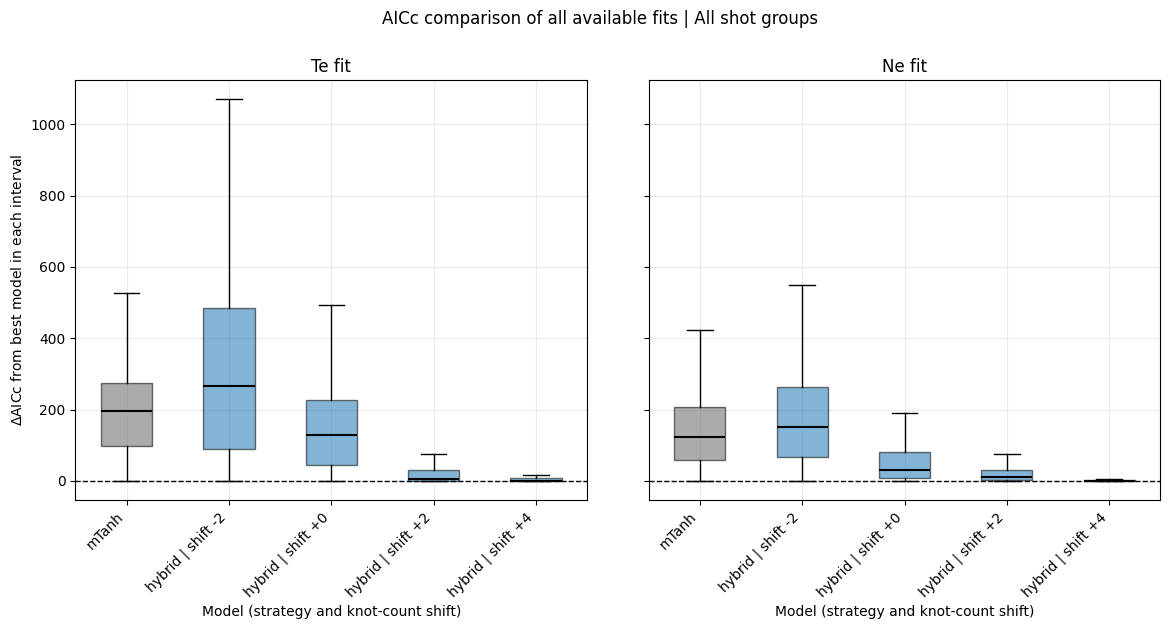

,quantity,model,intervals,median_delta_from_best,fraction_best,median_rank
9,Ne,hybrid | shift +4,709,0.000000,0.668547,1.0
8,Ne,hybrid | shift +2,710,9.964578,0.181690,2.0
7,Ne,hybrid | shift +0,710,29.078203,0.109859,3.0
5,Ne,mTanh,710,121.847905,0.033803,4.0
6,Ne,hybrid | shift -2,710,152.318888,0.007042,4.0
4,Te,hybrid | shift +4,709,0.000000,0.557123,1.0
3,Te,hybrid | shift +2,710,4.796694,0.384507,2.0
2,Te,hybrid | shift +0,710,127.968661,0.023944,3.0
0,Te,mTanh,710,195.310295,0.018310,4.0
1,Te,hybrid | shift -2,710,266.196107,0.016901,5.0


Each model is compared with the lowest-AICc model for the same interval and quantity.
Delta 0 means best (or tied); larger values mean less support relative to that interval's best fit.
AICc uses nominal coefficient counts; constrained-spline effective degrees of freedom may differ.


In [ ]:
import json

variant_keys = JOIN_KEYS + ['knot_strategy', 'knot_count_shift']
parameter_columns = ['Te_spline_parameters', 'Ne_spline_parameters']
required_scan_columns = set(
    variant_keys + parameter_columns + [
        'fit_success', 'Te_chi_squared', 'Ne_chi_squared',
    ]
)
missing_scan_columns = sorted(required_scan_columns.difference(scan_raw.columns))
if missing_scan_columns:
    raise ValueError(f'Scan CSV is missing AICc inputs: {missing_scan_columns}')

all_scan_variants = scan_raw.copy()
all_scan_variants['shot_id'] = pd.to_numeric(
    all_scan_variants['shot_id'], errors='raise').astype(int)
for time_column in ('t_begin', 't_end'):
    all_scan_variants[time_column] = pd.to_numeric(
        all_scan_variants[time_column], errors='coerce').round(9)
all_scan_variants['knot_count_shift'] = pd.to_numeric(
    all_scan_variants['knot_count_shift'], errors='raise').astype(int)
all_scan_variants['fit_success'] = (
    all_scan_variants['fit_success'].astype(str).str.strip().str.lower()
    .isin({'true', '1', 'yes'})
)
all_scan_variants = all_scan_variants.merge(
    shot_groups_raw[SHOT_GROUP_COLUMNS].drop_duplicates('shot_id'),
    on='shot_id',
    how='left',
    validate='many_to_one',
)
all_scan_variants['description'] = all_scan_variants['description'].fillna('Unclassified')
if GROUP_PATTERNS:
    group_regex = '|'.join(re.escape(pattern) for pattern in GROUP_PATTERNS)
    group_mask = all_scan_variants['description'].str.contains(
        group_regex, case=False, regex=True, na=False)
    all_scan_variants = all_scan_variants.loc[group_mask].copy()
all_scan_variants = all_scan_variants.loc[all_scan_variants['fit_success']].copy()
if all_scan_variants.duplicated(variant_keys).any():
    raise ValueError('The scan CSV contains duplicate interval/model combinations.')

fitted_for_aic = raw_fitted_csv.rename(columns={
    'shot': 'shot_id',
    't_begin (s)': 't_begin',
    't_end (s)': 't_end',
})
baseline_columns = JOIN_KEYS + [
    'n_points', 'mtanh_Te_weighted_sse', 'mtanh_Ne_weighted_sse',
]
missing_baseline_columns = sorted(
    set(baseline_columns).difference(fitted_for_aic.columns)
)
if missing_baseline_columns:
    raise ValueError(f'Fitted CSV is missing AICc inputs: {missing_baseline_columns}')
mtanh_baseline = fitted_for_aic.loc[:, baseline_columns].copy()
mtanh_baseline['shot_id'] = pd.to_numeric(
    mtanh_baseline['shot_id'], errors='raise').astype(int)
for time_column in ('t_begin', 't_end'):
    mtanh_baseline[time_column] = pd.to_numeric(
        mtanh_baseline[time_column], errors='coerce').round(9)
if mtanh_baseline.duplicated(JOIN_KEYS).any():
    raise ValueError('The fitted CSV has duplicate mTanh interval keys.')

all_aic_data = all_scan_variants.merge(
    mtanh_baseline,
    on=JOIN_KEYS,
    how='inner',
    validate='many_to_one',
)


def stored_parameter_count(value):
    if isinstance(value, (list, tuple, np.ndarray)):
        return len(value)
    if not isinstance(value, str) or not value.strip():
        return np.nan
    try:
        return len(json.loads(value))
    except (TypeError, ValueError):
        return np.nan


def configured_mtanh_parameter_count(quantity):
    quantity_config = (
        pipeline_config.get('fit_config', {})
        .get('fits', {})
        .get('mtanh', {})
        .get(quantity, {})
    )
    fixed_count = sum(
        quantity_config.get(name) is not None
        for name in ('fix_x0', 'fix_w', 'fix_a_tail')
    )
    return (
        2
        + int(quantity_config.get('deg_tail', 3)) + 1
        + int(quantity_config.get('deg_top', 3)) + 1
        - fixed_count
    )


def corrected_aic(chi_squared, parameter_count, n_points):
    chi_squared = pd.to_numeric(chi_squared, errors='coerce').to_numpy(float)
    parameter_count = pd.to_numeric(parameter_count, errors='coerce').to_numpy(float)
    n_points = pd.to_numeric(n_points, errors='coerce').to_numpy(float)
    values = np.full(chi_squared.shape, np.nan, dtype=float)
    valid = (
        np.isfinite(chi_squared)
        & np.isfinite(parameter_count)
        & np.isfinite(n_points)
        & (n_points > parameter_count + 1)
    )
    values[valid] = (
        chi_squared[valid]
        + 2.0 * parameter_count[valid]
        + 2.0 * parameter_count[valid] * (parameter_count[valid] + 1.0)
        / (n_points[valid] - parameter_count[valid] - 1.0)
    )
    return values


for quantity, parameter_column in (
    ('Te', 'Te_spline_parameters'),
    ('Ne', 'Ne_spline_parameters'),
):
    spline_count = all_aic_data[parameter_column].map(stored_parameter_count)
    mtanh_count = configured_mtanh_parameter_count(quantity)
    all_aic_data[f'{quantity}_spline_AICc'] = corrected_aic(
        all_aic_data[f'{quantity}_chi_squared'],
        spline_count,
        all_aic_data['n_points'],
    )
    all_aic_data[f'{quantity}_mtanh_AICc'] = corrected_aic(
        all_aic_data[f'mtanh_{quantity}_weighted_sse'],
        pd.Series(mtanh_count, index=all_aic_data.index),
        all_aic_data['n_points'],
    )

model_rows = []
for quantity in ('Te', 'Ne'):
    spline_models = all_aic_data.loc[:, JOIN_KEYS + [
        'knot_strategy', 'knot_count_shift', f'{quantity}_spline_AICc',
    ]].copy()
    spline_models['model'] = (
        spline_models['knot_strategy'].astype(str)
        + ' | shift '
        + spline_models['knot_count_shift'].map(lambda shift: f'{shift:+d}')
    )
    spline_models['AICc'] = spline_models.pop(f'{quantity}_spline_AICc')
    spline_models['quantity'] = quantity
    model_rows.append(spline_models.loc[:, JOIN_KEYS + ['quantity', 'model', 'AICc']])

    mtanh_models = all_aic_data.loc[:, JOIN_KEYS + [f'{quantity}_mtanh_AICc']].copy()
    mtanh_models = mtanh_models.drop_duplicates(JOIN_KEYS)
    mtanh_models['model'] = 'mTanh'
    mtanh_models['AICc'] = mtanh_models.pop(f'{quantity}_mtanh_AICc')
    mtanh_models['quantity'] = quantity
    model_rows.append(mtanh_models.loc[:, JOIN_KEYS + ['quantity', 'model', 'AICc']])

model_aic = pd.concat(model_rows, ignore_index=True).dropna(subset=['AICc'])
model_group_keys = ['quantity'] + JOIN_KEYS
model_aic['best_AICc'] = model_aic.groupby(model_group_keys)['AICc'].transform('min')
model_aic['delta_from_best'] = model_aic['AICc'] - model_aic['best_AICc']
model_aic['rank'] = model_aic.groupby(model_group_keys)['AICc'].rank(method='min')

variants = (
    all_aic_data[['knot_strategy', 'knot_count_shift']]
    .drop_duplicates()
    .sort_values(['knot_strategy', 'knot_count_shift'])
)
model_order = ['mTanh'] + [
    f'{row.knot_strategy} | shift {int(row.knot_count_shift):+d}'
    for row in variants.itertuples(index=False)
]
strategy_names = variants['knot_strategy'].astype(str).unique().tolist()
strategy_cmap = plt.get_cmap('tab10')
strategy_colors = {
    strategy: strategy_cmap(index % 10)
    for index, strategy in enumerate(strategy_names)
}
model_colors = {'mTanh': '0.4'}
for row in variants.itertuples(index=False):
    model_colors[f'{row.knot_strategy} | shift {int(row.knot_count_shift):+d}'] = (
        strategy_colors[str(row.knot_strategy)]
    )

summary_rows = []
figure_width = max(14.0, 0.52 * len(model_order))
fig, axes = plt.subplots(1, 2, figsize=(figure_width, 7), sharey=True)
fig.subplots_adjust(top=0.88, bottom=0.28, wspace=0.12)
for axis, quantity in zip(axes, ('Te', 'Ne')):
    distributions = []
    plotted_models = []
    for model in model_order:
        selected = model_aic.loc[
            model_aic['quantity'].eq(quantity) & model_aic['model'].eq(model)
        ]
        deltas = selected['delta_from_best'].to_numpy(float)
        ranks = selected['rank'].to_numpy(float)
        summary_rows.append({
            'quantity': quantity,
            'model': model,
            'intervals': deltas.size,
            'median_delta_from_best': np.median(deltas) if deltas.size else np.nan,
            'fraction_best': np.mean(np.isclose(deltas, 0.0)) if deltas.size else np.nan,
            'median_rank': np.median(ranks) if ranks.size else np.nan,
        })
        if deltas.size:
            distributions.append(deltas)
            plotted_models.append(model)

    if distributions:
        boxplot = axis.boxplot(
            distributions,
            patch_artist=True,
            showfliers=False,
            medianprops={'color': 'black', 'linewidth': 1.5},
        )
        for patch, model in zip(boxplot['boxes'], plotted_models):
            patch.set_facecolor(model_colors[model])
            patch.set_alpha(0.55)
        axis.set_xticks(np.arange(1, len(plotted_models) + 1))
        axis.set_xticklabels(plotted_models, rotation=45, ha='right')
    else:
        axis.text(
            0.5, 0.5, 'No valid AICc comparisons',
            ha='center', va='center', transform=axis.transAxes,
        )
    axis.axhline(0.0, color='black', linewidth=1.0, linestyle='--')
    axis.set_title(f'{quantity} fit')
    axis.set_xlabel('Model (strategy and knot-count shift)')

axes[0].set_ylabel(r'$\Delta\mathrm{AICc}$ from best model in each interval')
fig.suptitle(
    f'AICc comparison of all available fits | {selected_group_label}',
    y=0.98,
)
plt.show()

model_aic_summary = pd.DataFrame(summary_rows).sort_values(
    ['quantity', 'median_rank', 'median_delta_from_best'], na_position='last'
)
display(model_aic_summary)
print('Each model is compared with the lowest-AICc model for the same interval and quantity.')
print('Delta 0 means best (or tied); larger values mean less support relative to that interval\'s best fit.')
print('AICc uses nominal coefficient counts; constrained-spline effective degrees of freedom may differ.')

In [ ]:
latest_scan_summary = scan_raw.copy()
latest_scan_summary['shot_id'] = pd.to_numeric(
    latest_scan_summary['shot_id'], errors='raise').astype(int)
for time_column in ('t_begin', 't_end'):
    latest_scan_summary[time_column] = pd.to_numeric(
        latest_scan_summary[time_column], errors='coerce').round(9)
for status_column in ('spline_status', 'physics_status'):
    if status_column not in latest_scan_summary.columns:
        raise ValueError(f'Scan CSV has no {status_column!r} column; rerun the scan.')
    latest_scan_summary[status_column] = (
        latest_scan_summary[status_column].astype(str).str.strip().str.lower()
    )
# Fit convergence only; separatrix failures do not affect the fit comparison.
latest_scan_summary['fit_converged'] = latest_scan_summary['spline_status'].eq('ok')
# Status 'not_run' means the spline fit was never started.
latest_scan_summary['spline_attempted'] = latest_scan_summary['spline_status'].isin(['ok', 'failed'])
latest_scan_summary['separatrix_missing'] = (
    latest_scan_summary['fit_converged']
    & latest_scan_summary['physics_status'].eq('failed')
)
latest_scan_summary = latest_scan_summary.merge(
    shot_groups_raw[SHOT_GROUP_COLUMNS].drop_duplicates('shot_id'),
    on='shot_id',
    how='left',
    validate='many_to_one',
)
latest_scan_summary['description'] = latest_scan_summary['description'].fillna('Unclassified')
if GROUP_PATTERNS:
    group_regex = '|'.join(re.escape(pattern) for pattern in GROUP_PATTERNS)
    latest_scan_summary = latest_scan_summary.loc[
        latest_scan_summary['description'].str.contains(
            group_regex, case=False, regex=True, na=False)
    ].copy()
if latest_scan_summary.empty:
    raise ValueError('No rows from the latest scan match the selected shot group.')

latest_point_counts = raw_fitted_csv.rename(columns={
    'shot': 'shot_id',
    't_begin (s)': 't_begin',
    't_end (s)': 't_end',
}).loc[:, JOIN_KEYS + ['n_points']].copy()
latest_point_counts['shot_id'] = pd.to_numeric(
    latest_point_counts['shot_id'], errors='raise').astype(int)
for time_column in ('t_begin', 't_end'):
    latest_point_counts[time_column] = pd.to_numeric(
        latest_point_counts[time_column], errors='coerce').round(9)
latest_point_counts['n_points'] = pd.to_numeric(
    latest_point_counts['n_points'], errors='coerce')
if latest_point_counts.duplicated(JOIN_KEYS).any():
    raise ValueError('The fitted CSV has duplicate interval keys for n_points.')
latest_scan_summary = latest_scan_summary.merge(
    latest_point_counts,
    on=JOIN_KEYS,
    how='left',
    validate='many_to_one',
)

latest_scan_summary['_interval_key'] = list(map(
    tuple, latest_scan_summary.loc[:, JOIN_KEYS].to_numpy()))
latest_variant_keys = JOIN_KEYS + ['knot_strategy', 'knot_count_shift']
if latest_scan_summary.duplicated(latest_variant_keys).any():
    raise ValueError('The latest scan contains duplicate interval/model combinations.')
total_latest_intervals = latest_scan_summary['_interval_key'].nunique()
latest_fit_summary = (
    latest_scan_summary.groupby(
        ['knot_strategy', 'knot_count_shift'], dropna=False)
    .agg(
        attempted_intervals=('spline_attempted', 'sum'),
        spline_converged=('fit_converged', 'sum'),
        spline_fit_failed=('spline_status', lambda values: int(values.eq('failed').sum())),
        not_fitted=('spline_status', lambda values: int(values.eq('not_run').sum())),
        separatrix_missing=('separatrix_missing', 'sum'),
        actual_knot_counts=('n_knots', lambda values: sorted(
            pd.to_numeric(values, errors='coerce').dropna().astype(int).unique()
        )),
    )
    .reset_index()
)
print(f'Latest scan: {SCAN_CSV_PATH.name}')
print(f'Distinct intervals in selected group: {total_latest_intervals}')
display(latest_fit_summary)

latest_fit_baseline = fitted_raw.rename(columns={
    'shot': 'shot_id',
    't_begin (s)': 't_begin',
    't_end (s)': 't_end',
}).copy()
latest_fit_baseline['shot_id'] = pd.to_numeric(
    latest_fit_baseline['shot_id'], errors='raise').astype(int)
for time_column in ('t_begin', 't_end'):
    latest_fit_baseline[time_column] = pd.to_numeric(
        latest_fit_baseline[time_column], errors='coerce').round(9)
chi2_baseline_columns = JOIN_KEYS + [
    'mtanh_Te_weighted_sse', 'mtanh_Ne_weighted_sse', 'mtanh_status',
]
missing_chi2_baseline = sorted(
    set(chi2_baseline_columns).difference(latest_fit_baseline.columns)
)
if missing_chi2_baseline:
    raise ValueError(f'Fitted database is missing weighted-chi-squared fields: {missing_chi2_baseline}')
latest_fit_baseline = latest_fit_baseline.loc[:, chi2_baseline_columns]
if latest_fit_baseline.duplicated(JOIN_KEYS).any():
    raise ValueError('The fitted database has duplicate interval keys.')
latest_fit_baseline = latest_fit_baseline.merge(
    latest_point_counts,
    on=JOIN_KEYS,
    how='left',
    validate='one_to_one',
)
latest_fit_baseline['_interval_key'] = list(map(
    tuple, latest_fit_baseline.loc[:, JOIN_KEYS].to_numpy()))
scan_interval_keys = set(latest_scan_summary['_interval_key'])
mtanh_results = latest_fit_baseline.loc[
    latest_fit_baseline['_interval_key'].isin(scan_interval_keys)
].copy()
mtanh_te = pd.to_numeric(
    mtanh_results['mtanh_Te_weighted_sse'], errors='coerce').to_numpy(float)
mtanh_ne = pd.to_numeric(
    mtanh_results['mtanh_Ne_weighted_sse'], errors='coerce').to_numpy(float)
mtanh_converged_keys = set(mtanh_results.loc[
    np.isfinite(mtanh_te) & np.isfinite(mtanh_ne), '_interval_key'
])
mtanh_run_keys = set(mtanh_results.loc[
    mtanh_results['mtanh_status'].isin(['ok', 'failed']), '_interval_key'
])
# mTanh is compared on the intervals where a spline fit was attempted.
mtanh_attempted_keys = set(latest_scan_summary.loc[
    latest_scan_summary['spline_attempted'], '_interval_key'
])
mtanh_not_run_count = len(mtanh_attempted_keys - mtanh_run_keys)
mtanh_converged_keys = mtanh_converged_keys & mtanh_attempted_keys
spline_converged_keys = [
    set(variant_rows.loc[variant_rows['fit_converged'], '_interval_key'])
    for _, variant_rows in latest_scan_summary.groupby(
        ['knot_strategy', 'knot_count_shift'], dropna=False)
]
common_interval_keys = mtanh_converged_keys.intersection(*spline_converged_keys)
common_interval_count = len(common_interval_keys)
print(
    f'mTanh fits converged: {len(mtanh_converged_keys)} of {len(mtanh_attempted_keys)} '
    f'spline-attempted intervals ({mtanh_not_run_count} with no mTanh run)'
)
print(
    f'Intervals where mTanh and every spline variant converged: '
    f'{common_interval_count} of {total_latest_intervals}'
)
mtanh_common = mtanh_results.loc[
    mtanh_results['_interval_key'].isin(common_interval_keys)
].copy()

model_stats = {
    'mTanh': {
        'model': 'mTanh',
        'fit converged': len(mtanh_converged_keys),
        'attempted fits': len(mtanh_attempted_keys),
        'common intervals': common_interval_count,
    }
}
for quantity in ('Te', 'Ne'):
    raw_values = pd.to_numeric(
        mtanh_common[f'mtanh_{quantity}_weighted_sse'], errors='coerce'
    ).to_numpy(float)
    point_counts = pd.to_numeric(
        mtanh_common['n_points'], errors='coerce').to_numpy(float)
    valid_values = (
        np.isfinite(raw_values)
        & np.isfinite(point_counts)
        & (point_counts > 0.0)
    )
    values = raw_values[valid_values]
    point_counts = point_counts[valid_values]
    parameter_count = configured_mtanh_parameter_count(quantity)
    aic_values = values + 2.0 * parameter_count
    bic_values = values + parameter_count * np.log(point_counts)
    model_stats['mTanh'][f'{quantity}_n'] = values.size
    model_stats['mTanh'][f'{quantity}_mean'] = np.mean(values) if values.size else np.nan
    model_stats['mTanh'][f'{quantity}_median'] = np.median(values) if values.size else np.nan
    model_stats['mTanh'][f'{quantity}_median_aic'] = (
        np.median(aic_values) if values.size else np.nan
    )
    model_stats['mTanh'][f'{quantity}_median_bic'] = (
        np.median(bic_values) if values.size else np.nan
    )

for (strategy, shift), variant_data in latest_scan_summary.groupby(
    ['knot_strategy', 'knot_count_shift'], dropna=False
):
    model = f'{strategy} | shift {int(shift):+d}'
    common_data = variant_data.loc[
        variant_data['_interval_key'].isin(common_interval_keys)
    ]
    model_stats[model] = {
        'model': model,
        'fit converged': variant_data.loc[
            variant_data['fit_converged'], '_interval_key'].nunique(),
        'attempted fits': variant_data.loc[
            variant_data['spline_attempted'], '_interval_key'].nunique(),
        'common intervals': common_data['_interval_key'].nunique(),
    }
    for quantity, parameter_column in (
        ('Te', 'Te_spline_parameters'),
        ('Ne', 'Ne_spline_parameters'),
    ):
        raw_values = pd.to_numeric(
            common_data[f'{quantity}_chi_squared'], errors='coerce'
        ).to_numpy(float)
        parameter_counts = common_data[parameter_column].map(
            stored_parameter_count
        ).to_numpy(float)
        point_counts = pd.to_numeric(
            common_data['n_points'], errors='coerce').to_numpy(float)
        valid_values = (
            np.isfinite(raw_values)
            & np.isfinite(parameter_counts)
            & np.isfinite(point_counts)
            & (point_counts > 0.0)
        )
        values = raw_values[valid_values]
        parameter_counts = parameter_counts[valid_values]
        point_counts = point_counts[valid_values]
        aic_values = values + 2.0 * parameter_counts
        bic_values = values + parameter_counts * np.log(point_counts)
        model_stats[model][f'{quantity}_n'] = values.size
        model_stats[model][f'{quantity}_mean'] = np.mean(values) if values.size else np.nan
        model_stats[model][f'{quantity}_median'] = np.median(values) if values.size else np.nan
        model_stats[model][f'{quantity}_median_aic'] = (
            np.median(aic_values) if values.size else np.nan
        )
        model_stats[model][f'{quantity}_median_bic'] = (
            np.median(bic_values) if values.size else np.nan
        )

chi2_summary = pd.DataFrame(model_stats.values()).rename(columns={
    'Te_n': 'Te intervals',
    'Te_mean': 'Te mean chi2',
    'Te_median': 'Te median chi2',
    'Te_median_aic': 'Te median AIC',
    'Te_median_bic': 'Te median BIC',
    'Ne_n': 'Ne intervals',
    'Ne_mean': 'Ne mean chi2',
    'Ne_median': 'Ne median chi2',
    'Ne_median_aic': 'Ne median AIC',
    'Ne_median_bic': 'Ne median BIC',
})
chi2_summary = chi2_summary.drop(columns=['Te intervals', 'Ne intervals'])
print(
    f'Raw weighted chi-squared, median AIC, and median BIC over the '
    f'{common_interval_count} intervals where mTanh and every spline variant converged:'
)
display(chi2_summary)
print('AIC is defined as -2 ln(L_max) + 2k (Akaike, 1974); here weighted chi-squared substitutes for -2 ln(L_max).')
print('This substitution is valid up to model-independent constants for independent Gaussian errors with known variances, when comparing the same observations.')
print('BIC is calculated as weighted chi-squared + k ln(n_points), under the same likelihood assumptions.')
print('Reference: Akaike, H. (1974). A new look at the statistical model identification. IEEE Transactions on Automatic Control, 19(6), 716-723. doi:10.1109/TAC.1974.1100705.')


Latest scan: spline_knot_scan_20261019_173111.csv
Distinct intervals in selected group: 752


,knot_strategy,knot_count_shift,attempted_intervals,spline_converged,spline_fit_failed,not_fitted,separatrix_missing,actual_knot_counts
0,hybrid,-2,740,725,15,12,14,"[12, 13, 14, 15, 16, 17]"
1,hybrid,0,740,725,15,12,14,"[14, 15, 16, 17, 18, 19]"
2,hybrid,2,740,725,15,12,14,"[16, 17, 18, 19, 20, 21]"
3,hybrid,4,740,724,16,12,14,"[18, 19, 20, 21, 22, 23]"


mTanh fits converged: 724 of 740 spline-attempted intervals (15 with no mTanh run)
Intervals where mTanh and every spline variant converged: 723 of 752
Raw weighted chi-squared, median AIC, and median BIC over the 723 intervals where mTanh and every spline variant converged:


,model,fit converged,attempted fits,common intervals,Te mean chi2,Te median chi2,Te median AIC,Te median BIC,Ne mean chi2,Ne median chi2,Ne median AIC,Ne median BIC
0,mTanh,724,740,723,1.098159e+03,1084.169823,1098.169823,1122.604292,1.384083e+03,1292.998628,1308.998628,1333.283873
1,hybrid | shift -2,725,740,723,1.211387e+03,1153.127620,1185.127620,1238.138915,1.411716e+03,1316.986984,1348.986984,1401.913686
2,hybrid | shift +0,725,740,723,1.026010e+03,1019.725235,1053.986360,1110.594597,1.268792e+03,1168.427226,1206.680704,1264.692116
3,hybrid | shift +2,725,740,723,8.961389e+02,863.508030,903.508030,968.335502,1.228102e+03,1135.334159,1175.493940,1239.772021
4,hybrid | shift +4,724,740,723,1.979317e+15,842.334149,886.334149,959.230406,1.808865e+14,1121.617411,1168.029814,1241.202681


AIC is defined as -2 ln(L_max) + 2k (Akaike, 1974); here weighted chi-squared substitutes for -2 ln(L_max).
This substitution is valid up to model-independent constants for independent Gaussian errors with known variances, when comparing the same observations.
BIC is calculated as weighted chi-squared + k ln(n_points), under the same likelihood assumptions.
Reference: Akaike, H. (1974). A new look at the statistical model identification. IEEE Transactions on Automatic Control, 19(6), 716-723. doi:10.1109/TAC.1974.1100705.


In [ ]:
# Fit success is converged fits over attempted fits; median AIC and BIC are over common intervals.
median_information_table = chi2_summary.loc[:, [
    'model',
    'fit converged',
    'attempted fits',
    'Te median AIC',
    'Te median BIC',
    'Ne median AIC',
    'Ne median BIC',
]].rename(columns={
    'model': 'Model',
    'fit converged': 'Converged',
    'attempted fits': 'Attempted',
}).reset_index(drop=True)
median_information_table.insert(
    3, 'Success [%]',
    100.0 * median_information_table['Converged'] / median_information_table['Attempted'],
)

display(median_information_table.round(1))


,Model,Converged,Attempted,Success [%],Te median AIC,Te median BIC,Ne median AIC,Ne median BIC
0,mTanh,724,740,97.8,1098.2,1122.6,1309.0,1333.3
1,hybrid | shift -2,725,740,98.0,1185.1,1238.1,1349.0,1401.9
2,hybrid | shift +0,725,740,98.0,1054.0,1110.6,1206.7,1264.7
3,hybrid | shift +2,725,740,98.0,903.5,968.3,1175.5,1239.8
4,hybrid | shift +4,724,740,97.8,886.3,959.2,1168.0,1241.2


In [ ]:
def latex_model_label(model):
    if model == 'mTanh':
        return 'mTanh'
    strategy, shift_text = model.split(' | shift ')
    shift_value = int(shift_text)
    shift_latex = '0' if shift_value == 0 else f'{shift_value:+d}'
    return f"{STRATEGY_LABELS.get(strategy, strategy)}, shift ${shift_latex}$"


def latex_value(value):
    return '--' if pd.isna(value) else f'{value:.1f}'


def latex_fit_success(row):
    return (
        f"{int(row['Converged'])}/{int(row['Attempted'])} "
        f"({row['Success [%]']:.1f}" + r'\%)'
    )


latex_body_rows = []
for _, row in median_information_table.iterrows():
    values = [
        latex_value(row[column])
        for column in (
            'Te median AIC', 'Te median BIC', 'Ne median AIC', 'Ne median BIC')
    ]
    latex_body_rows.append(
        f"{latex_model_label(row['Model'])} & {latex_fit_success(row)} & "
        + ' & '.join(values) + r' \\'
    )

tabular_lines = [
    r'\begin{tabular}{l c rr rr}',
    r'\toprule',
    r' & & \multicolumn{2}{c}{$T_e$ fits} & \multicolumn{2}{c}{$n_e$ fits} \\',
    r'\cmidrule(lr){3-4} \cmidrule(lr){5-6}',
    r'Model & Fit success & Median AIC & Median BIC & Median AIC & Median BIC \\',
    r'\midrule',
    *latex_body_rows,
    r'\bottomrule',
    r'\end{tabular}',
]
caption_text = (
    'Fit success and median AIC and BIC for the mTanh fits and the '
    f'{strategy_label} spline fits at each knot-count shift. '
    'Fit success is converged fits over attempted fits; separatrix power-balance failures do not count against it. '
    f'The mTanh row uses the {len(mtanh_attempted_keys)} intervals where a spline fit was attempted; '
    f'mTanh was not run on {mtanh_not_run_count} of them (spline fit failed), and these are counted as not converged. '
    f'Median AIC and BIC are over the {common_interval_count} intervals where '
    'all fits converged. Lower values indicate better fits.'
)
latex_median_table = '\n'.join([
    r'\includetable{%',
    r'\caption{' + caption_text + '}',
    r'\label{tab:median-aic-bic-knot-scan}',
    r'\small',
    *tabular_lines,
    '}',
])
print(latex_median_table)


\includetable{%
\caption{Fit success and median AIC and BIC for the mTanh fits and the Hybrid spline fits at each knot-count shift. Fit success is converged fits over attempted fits; separatrix power-balance failures do not count against it. The mTanh row uses the 740 intervals where a spline fit was attempted; mTanh was not run on 15 of them (spline fit failed), and these are counted as not converged. Median AIC and BIC are over the 723 intervals where all fits converged. Lower values indicate better fits.}
\label{tab:median-aic-bic-knot-scan}
\small
\begin{tabular}{l c rr rr}
\toprule
 & & \multicolumn{2}{c}{$T_e$ fits} & \multicolumn{2}{c}{$n_e$ fits} \\
\cmidrule(lr){3-4} \cmidrule(lr){5-6}
Model & Fit success & Median AIC & Median BIC & Median AIC & Median BIC \\
\midrule
mTanh & 724/740 (97.8\%) & 1098.2 & 1122.6 & 1309.0 & 1333.3 \\
Hybrid, shift $-2$ & 725/740 (98.0\%) & 1185.1 & 1238.1 & 1349.0 & 1401.9 \\
Hybrid, shift $0$ & 725/740 (98.0\%) & 1054.0 & 1110.6 & 1206.7 & 1264.